## to do:

QoL
- plot nodes at any level of transform, see all_nodes
- automatically perform max. level transform
- plot single node by path
- time [s] instead of coefficient number
- automatically perform nodes2data on inverse
- fix plots

visualisation:
- graph neural network (python package)
- add scientific form to heisenberg plot
- add automatic ticks formatting to heisenberg plot?

studentship:
- sensitivity analysis
- testing/tuning thresholding values (classification without machine learning)
- validate kurtosis and crest factor
- test border effects on kurtosis and crest factor
- test with data length of power of 2
- develop classifier
- clustering (e.g. k-means) using energy, kurtosis, crest factor is input features.
- 8 pages for manuscript
- normalise clustering
- look at effect of number of clusters
- learn about k-means and how it's used (reaserch)
- look at how it's used with dwpt
- explain and justify procedure for classification using research
- ksvd, knn
- settle on a method by next meeting

# Decompose a signal to its components at different frequency bands with WPT

In this notebook we aim to test WPT for extracting different components of a signal based on the energy, kurtosis, and crest factor of different frequency bands. The WPT library requires python3.6+ version. The following cell checks this requirement.

In [52]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

Import the wavelet_transform package and required libraries.

In [53]:
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot

# matplotlib.use('nbagg')
import matplotlib.pyplot as plt
import numpy as np
import pywt
import scipy.stats as sc

Specify the parameters for generating a synthetic signal and to perform wavelet packet transform.

In [54]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [0.5, 0.4, 0.4]  # amplitude of each sine wave
frequencies = [5, 15, 25]  # frequency content of signal
phases = [0, np.deg2rad(45), np.deg2rad(120)]  # phase of each sine wave

duration = 1000 / min(frequencies)  # duration of wave

trans_amp = [10 for _ in range(5)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db30"
levels = 6
mode = "symmetric"

sort_by = 'energy'  # 'energy', 'kurtosis', 'crest', 'False' -> freq
sort = "rec"  # 'rec' (reconstructed signal) 'coef' (transform coefficients)
n_highest = 3

fft_lim = 50  # increase value to view more of the fft plots

Generate synthetic multitonal signal with/without additive noise. We will fft the signal to double check the frequency contents.

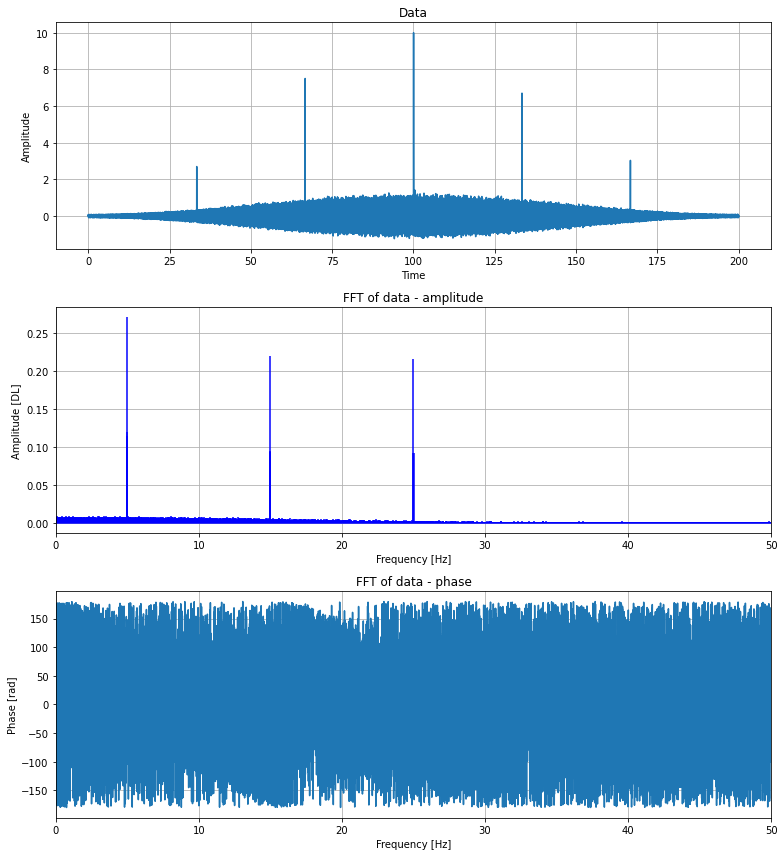

In [55]:
# generate sound wave
data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
data += sd.transients(trans_amp, trans_time, trans_dur, duration, sampling_rate)
data += sd.noise(std_noise,duration,sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

### Frequency content of reconstructed subbands
Decompose signal using discrete wavelet packet transform and sort the nodes in order of energy, kurtosis, or crest factor.

functions used for sorting

In [56]:
def calc_crest_factor(array):
    rms = np.sqrt(1 / len(array) * sum(array**2))
    return 10 * np.log10(max(array**2) / rms)


def calc_energy(array):
    return 1 / len(array) * sum(array**2)


def sort_nodes(rec, sort="rec", sort_by="energy"):
    """
    choose how to sort the subbands

    Parameters
    ----------
    rec: tuple
        tuple containing (coefficients,reconstructed_wave,fft_of_rec_wave,energy,kurtosis,crest)
    sort: str
        sort by 'energy', 'kurtosis', or 'crest' factor
    coef_or_rec: str
        sort by calculating attributes of the node coefficients or the reconstructed wave

    returns
    -------
    rec: tuple
        sorted input
    """
    if sort == "rec":
        if sort_by == "energy": 
            return sorted(rec, key=lambda x: x[3], reverse=True)
        elif sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[4], reverse=True)
        elif sort_by == "crest":
            return sorted(rec, key=lambda x: x[4], reverse=True)
            


    elif sort == "coef":
        if sort_by == "energy":
            return sorted(rec, key=lambda x: x[0].energy, reverse=True)
        if sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[0].kurtosis, reverse=True)
        if sort_by == "crest":
            return sorted(rec, key=lambda x: x[0].crest_factor, reverse=True)

Transform and sort nodes

In [57]:
# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
rec = []

for node in tr_ob.get_level(order="freq"):
    path = node.path
    rec_nodes = tr_ob.packet_nodes_for_rec(keep=[path])
    coeffs = tr_ob.nodes2data(rec_nodes)
    inverse = inv.inv_dwpt(coeffs, wavelet)[:signal_length]
    inverse_signal_length = len(inverse)
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )
    energy = calc_energy(inverse)
    kurtosis = sc.kurtosis(inverse)
    crest = calc_crest_factor(inverse)
    rec.append((node, inverse, fft, energy, kurtosis, crest))

plot the **`n_highest`** energy components (subbands).

In [58]:
def plot_reconstructions(rec, n_highest=None, group=None):
    partial_rec = np.zeros(signal_length)  # track sum of highest energy subbands
    if n_highest is None:
        n_highest = len(rec)
    for i, rec in enumerate(rec[:n_highest]):  # highest energy, kurtosis, etc.
        node, rec_wave, fft, *_ = rec
        partial_rec += rec_wave  # full reconstruction
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = node.frequency_range
        ax[0].plot(t_plot, rec_wave)
        title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(fft),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed subband")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()

        # print info
        print(f"energy of recovered signal: {calc_energy(rec_wave)}")
        print(f"kurtosis of recovered signal: {sc.kurtosis(rec_wave)}")
        print(f"crest factor of recovered signal: {calc_crest_factor(rec_wave)}")
        print()
        print(f"energy of node coefficients: {node.energy}")
        print(f"kurtosis of node coefficients: {node.kurtosis}")
        print(f"crest factor of node coefficients: {node.crest_factor}")
    return partial_rec

run = False
if run is True:
    # sort reconstructed waves
    sorted_rec = sort_nodes(rec, sort, sort_by)
    print(f"sorted by: {sort_by} of {sort}")
    # plot highest energy subbands
    partial_rec = plot_reconstructions(sorted_rec,n_highest)

### heisenberg visualisation

Making an heisenberg plot of the last level of dwpt

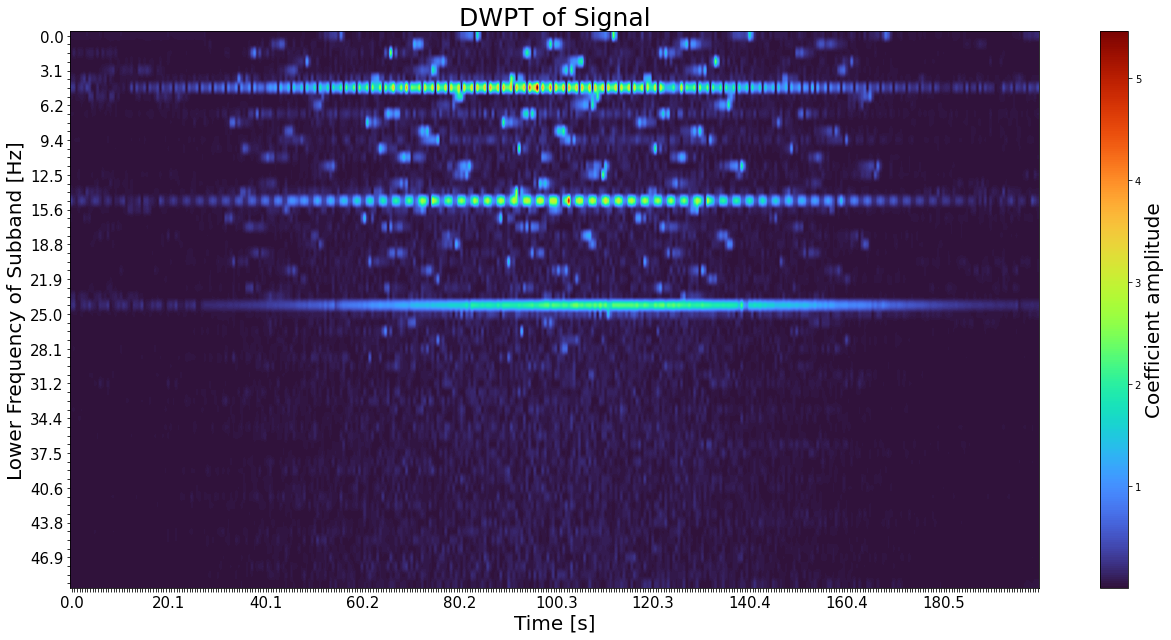

In [59]:
plot.heisenberg(tr_ob, max(t_plot))

### Clustering

k-means clustering algorithm with energy, kurtosis, and crest factor as the input

In [60]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
data_train = []
for _,inverse,_,energy,kurtosis,crest in rec:
    data_train.append(
        (energy, kurtosis, crest, max(abs(inverse)), 
         np.mean(inverse), sc.skew(inverse))
        )

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 5
kmeans = KMeans(n_clusters=no_clusters)
kmeans.fit(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

### Reassigning Groups

Post-hoc reassignment of groups based on the energy and kurtosis of their clusters.

In [61]:
def assign_labels(centers, labels, sort_by=1):
    """
    assign labels to clusters. Assign the highest cluster number to the centre with 
    highest energy. Then assign the rest in order of sort_by. The group numbers are reassigned
    to 1-indexed groups.

    Paramaters
    -----------
    centers: array
        array where each row is a centre of a cluster
    labels: list
        list of group assignments to reassign
    sort_by: int
        always sort out the highest energy because the harmonic can be separated
        from the rest by its much greater energy. Otherwise, sort by attribute
        number = sort_by of the centres.
    """
    # sort labels by energy, highest cluster energy is highest group number
    sort_by_energy = np.argsort(centers[:, 0])

    # sort rest of the labels by kurtosis
    sort_rest = np.argsort(centers[:, sort_by])

    sort_rest = np.delete(
        sort_rest, # delete highest energy group form kurtosis
        np.where(sort_rest == sort_by_energy[-1])[0][0], 
        axis=0
        )
    sort_rest = np.append(sort_rest, None)

    # create mapping from old cluster labels to new cluster labels
    mapping = {}
    for new_label, index in enumerate(zip(sort_by_energy, sort_rest)):
        if new_label == len(sort_by_energy) - 1:  # highest group no has highest energy
            mapping[index[0]] = new_label + 1
        else:
            mapping[index[1]] = new_label + 1  # other group numbers are arranged by kurtosis

    # update labels
    reassigned_labels = [mapping[label] for label in labels]
    return reassigned_labels

In [62]:
reassigned_labels = assign_labels(centers, labels)

### plot result

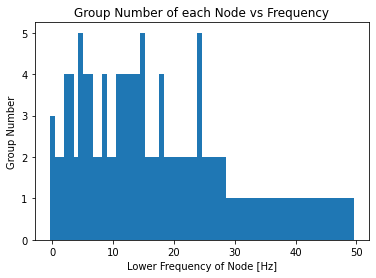

Cluster labels: [3, 2, 2, 4, 4, 2, 5, 4, 4, 2, 2, 4, 2, 2, 4, 4, 4, 4, 4, 5, 2, 2, 2, 4, 2, 2, 2, 2, 2, 2, 2, 5, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
highest energy: 3
highest kurtosis: 1
highest crest factor: 1


In [63]:
# plot regular k-means
plt.bar([node.frequency_range[0] for node,*_ in rec], reassigned_labels)
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

print("Cluster labels:", reassigned_labels)
print(f"highest energy: {np.argmax(centers[:,0])}")
print(f'highest kurtosis: {np.argmax(centers[:,1])}')
print(f'highest crest factor: {np.argmax(centers[:,2])}')

### PCA

In [64]:
# apply PCA to training data
pca = PCA(n_components=6)
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters)
kmeans_pca.fit(data_pca)

labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(pca.inverse_transform(kmeans_pca.cluster_centers_))
reassigned_pca_labels = assign_labels(centers_pca, labels_pca)

### Plot PCA Result

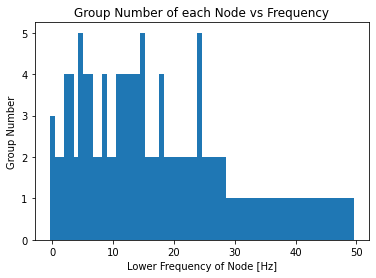

Eigenvectors:
Energy, Kurtosis, Crest factor, Peak, Mean
[[ 0.16  0.49  0.56  0.54  0.25  0.25]
 [-0.16 -0.15 -0.2  -0.23  0.66  0.66]
 [ 0.84 -0.45 -0.16  0.25  0.07  0.07]
 [ 0.31  0.73 -0.6  -0.14  0.01 -0.  ]
 [ 0.38  0.12  0.52 -0.76  0.02 -0.01]
 [ 0.01  0.01  0.   -0.01 -0.71  0.71]]
Eigenvalues: [2.74 1.93 1.24 0.13 0.04 0.  ]
Cluster labels: [1 4 4 2 2 4 3 2 2 4 4 2 4 4 2 2 2 2 2 3 4 4 4 2 4 4 4 4 4 4 4 3 4 4 4 4 4
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
highest PC1: 3
highest PC2: 2
highest PC3: 2


In [65]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node,*_ in rec]
plt.bar([node.frequency_range[0] for node,*_ in rec], reassigned_pca_labels)
plt.tick_params
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print('Energy, Kurtosis, Crest factor, Peak, Mean')
print(np.round(eigenvectors,2))

print("Eigenvalues:", np.round(eigenvalues,2))

print("Cluster labels:", labels_pca)
print(f"highest PC1: {np.argmax(centers_pca[:,0])}")
print(f'highest PC2: {np.argmax(centers_pca[:,1])}')
print(f'highest PC3: {np.argmax(centers_pca[:,2])}')

### 3d plot

3d plots of the results with axes energy, kurtosis, crest factor

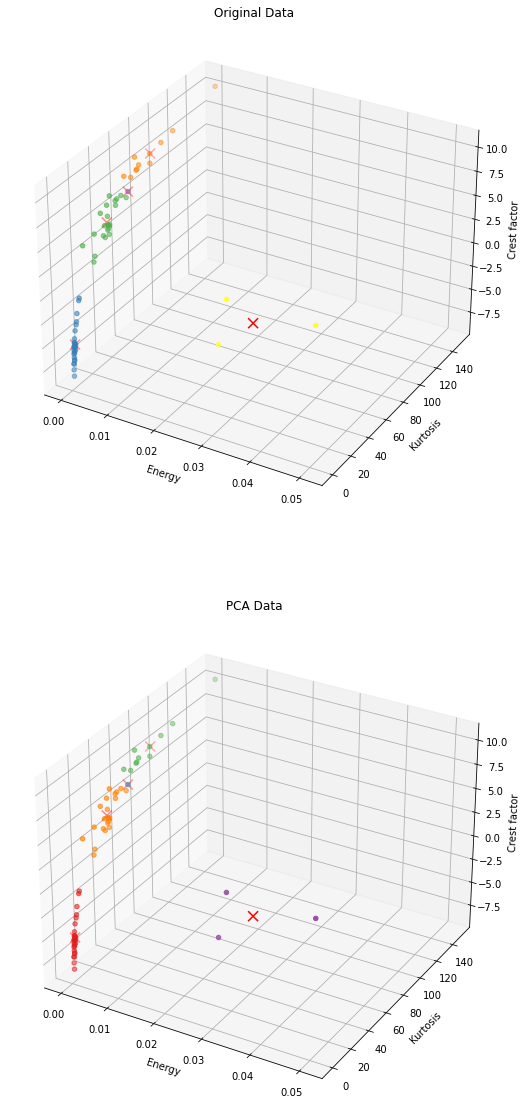

In [66]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={'projection': '3d'})

titles = ['Original Data', 'PCA Data']

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap('Set1')
    if i == 0:
        data_scatter = data_train
        centers_scatter = centers
        labels_scatter = reassigned_labels
    else:
        data_scatter = data_train
        centers_scatter = centers_pca
        labels_scatter = labels_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        c=[cmap(label) for label in labels_scatter])
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c='red', marker='x', s=100)
    
    ax.set_xlabel('Energy')
    ax.set_ylabel('Kurtosis')
    ax.set_zlabel('Crest factor')
    ax.set_title(titles[i])

plt.show()

### 2d plot

plots with energy vs crest factor comparing PCA and no PCA results

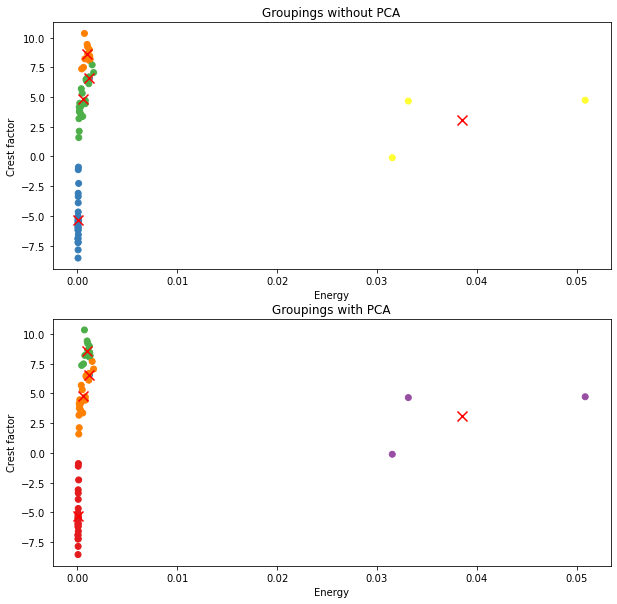

In [67]:
# 3d plot
fig, ax = plt.subplots(2,figsize=(10,10))

# plot with colours for each cluster
cmap = plt.cm.get_cmap('Set1')

data_scatter = data_train
labels_scatter = reassigned_labels
ax[0].scatter(
    [point[0] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=[cmap(label) for label in labels_scatter]
)
labels_scatter = labels_pca
ax[1].scatter(
    [point[0] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=[cmap(label) for label in labels_scatter]
)
# plot centres
centers_scatter = centers
ax[0].scatter(centers_scatter[:, 0], 
           centers_scatter[:, 2], c='red', marker='x', s=100)
centers_scatter = centers_pca
ax[1].scatter(centers_scatter[:, 0], 
           centers_scatter[:, 2], c='red', marker='x', s=100)
for i in range(2):
    ax[i].set_xlabel('Energy')
    ax[i].set_ylabel('Crest factor')
ax[0].set_title('Groupings without PCA')
ax[1].set_title('Groupings with PCA')
plt.show()

### Results

Plotting the reconstructed waves from clustering with their assigned group

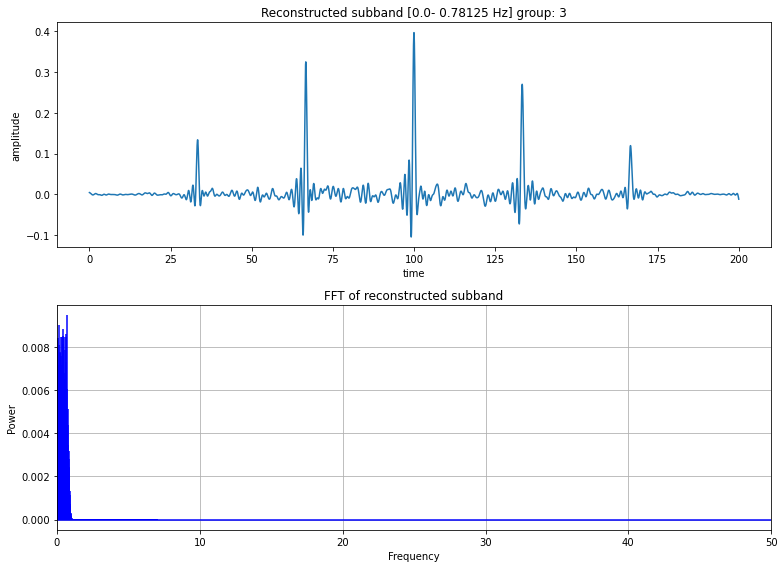

energy of recovered signal: 0.001198471554817712
kurtosis of recovered signal: 55.22140019814969
crest factor of recovered signal: 6.566765357661927

energy of node coefficients: 0.06538792980356767
kurtosis of node coefficients: 34.46797724720798
crest factor of node coefficients: 13.679682278225355


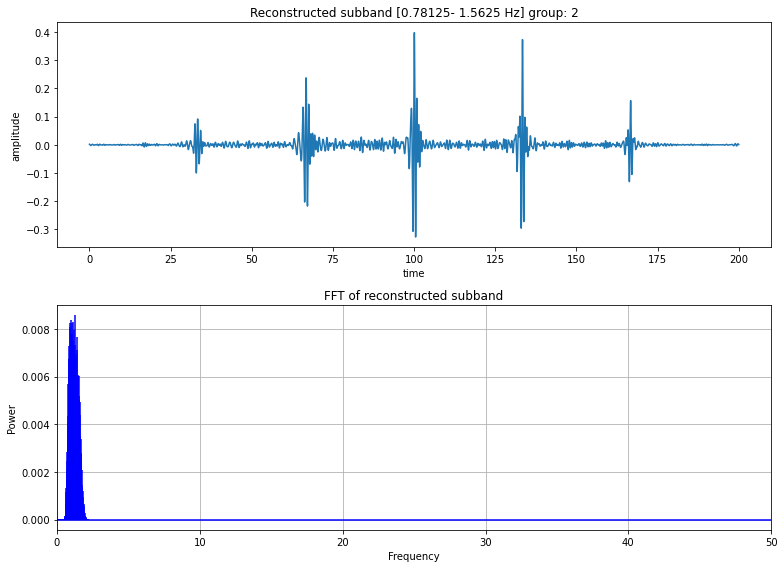

energy of recovered signal: 0.001152682870437116
kurtosis of recovered signal: 48.41971727518623
crest factor of recovered signal: 6.6930007886715455

energy of node coefficients: 0.06241435121425007
kurtosis of node coefficients: 23.255820858624226
crest factor of node coefficients: 12.29759124807571


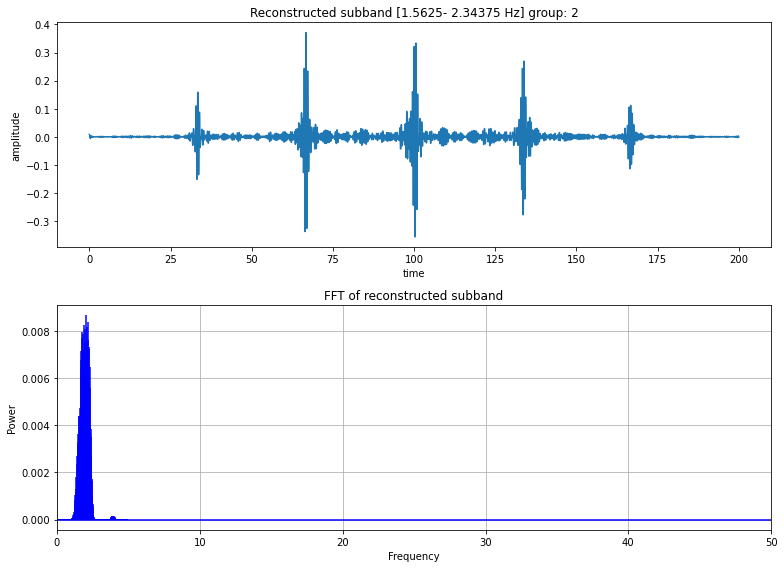

energy of recovered signal: 0.0011323542438876535
kurtosis of recovered signal: 42.93506823662007
crest factor of recovered signal: 6.116118259918179

energy of node coefficients: 0.06143238032793127
kurtosis of node coefficients: 46.37930039248211
crest factor of node coefficients: 14.138049574299707


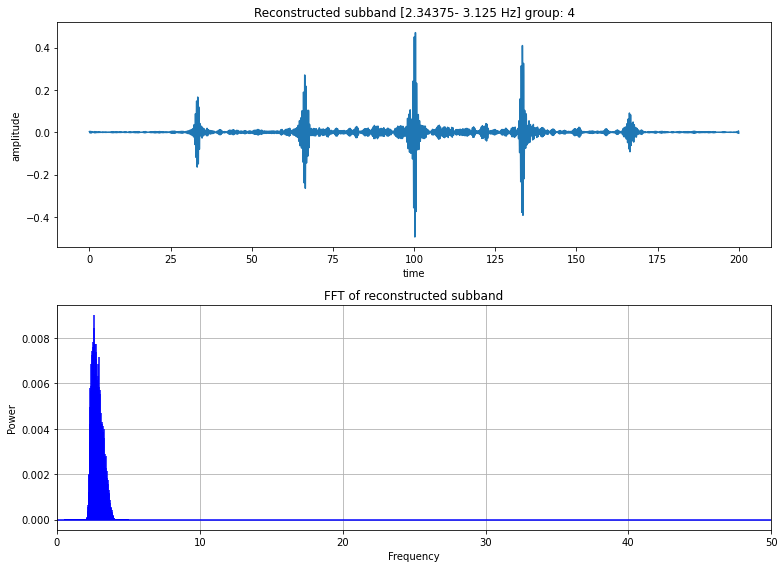

energy of recovered signal: 0.001227720673943468
kurtosis of recovered signal: 66.4784636362496
crest factor of recovered signal: 8.44770334722498

energy of node coefficients: 0.06642993636623476
kurtosis of node coefficients: 38.45781357345214
crest factor of node coefficients: 13.587357645269


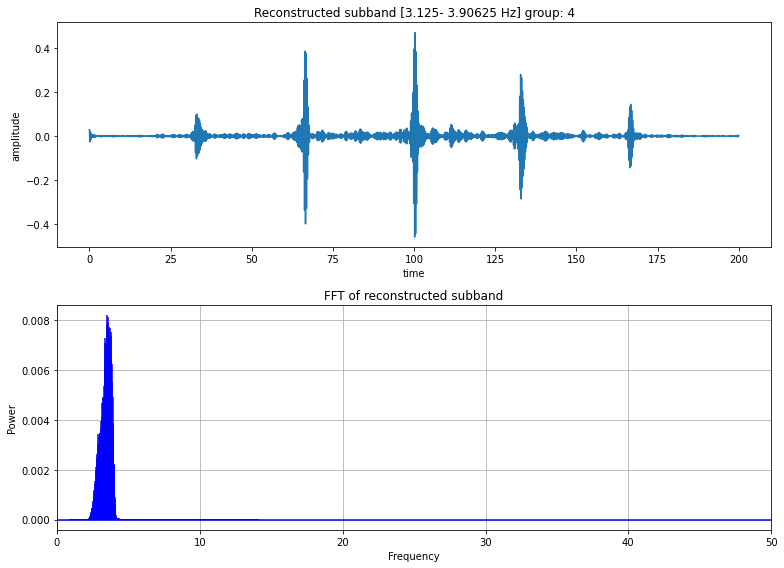

energy of recovered signal: 0.0011663065928172445
kurtosis of recovered signal: 64.06057370685889
crest factor of recovered signal: 8.079635542126566

energy of node coefficients: 0.06369182446921623
kurtosis of node coefficients: 29.925748998376065
crest factor of node coefficients: 12.241723609571626


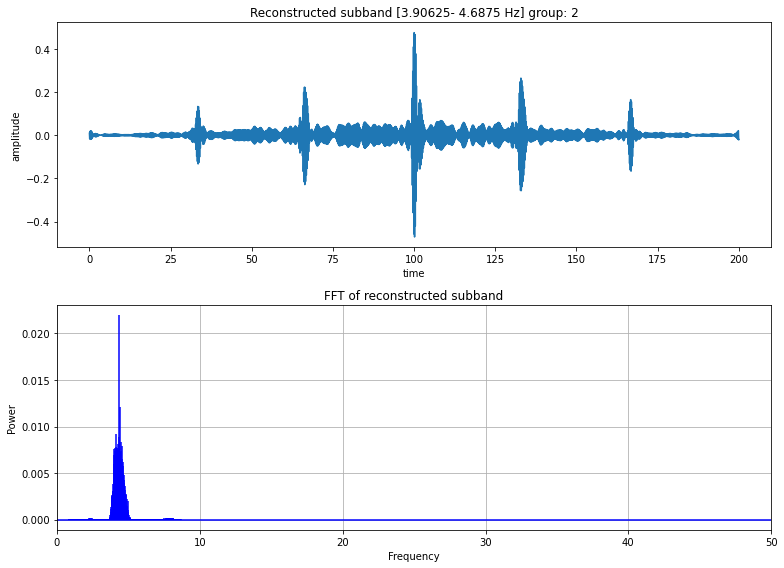

energy of recovered signal: 0.0014713198926316218
kurtosis of recovered signal: 35.73655982120589
crest factor of recovered signal: 7.700352850318485

energy of node coefficients: 0.08035417613723778
kurtosis of node coefficients: 23.536866472081105
crest factor of node coefficients: 13.4272871648123


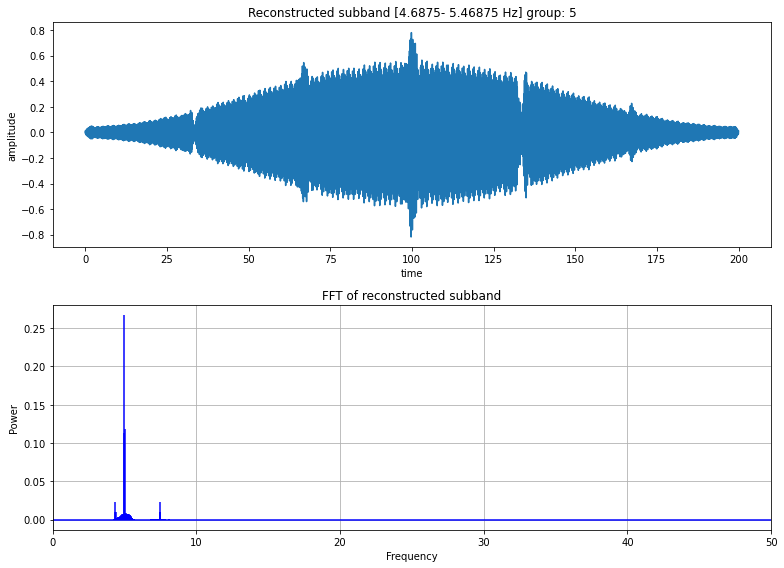

energy of recovered signal: 0.050857219795475965
kurtosis of recovered signal: -0.02943107958924296
crest factor of recovered signal: 4.724224742438256

energy of node coefficients: 2.755278897276397
kurtosis of node coefficients: 0.42677891383680944
crest factor of node coefficients: 12.537722481081628


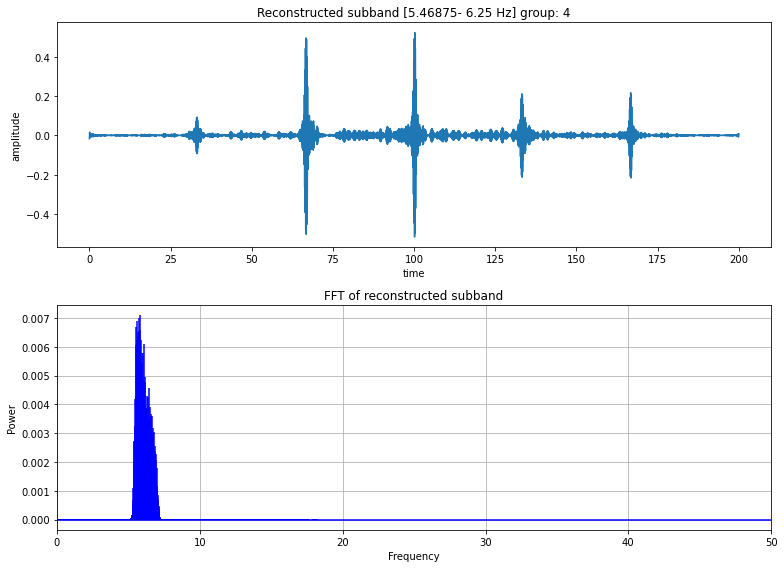

energy of recovered signal: 0.00118857170886661
kurtosis of recovered signal: 89.7461501618396
crest factor of recovered signal: 8.986013281194744

energy of node coefficients: 0.06542333139121499
kurtosis of node coefficients: 33.707582201897516
crest factor of node coefficients: 12.558937808407048


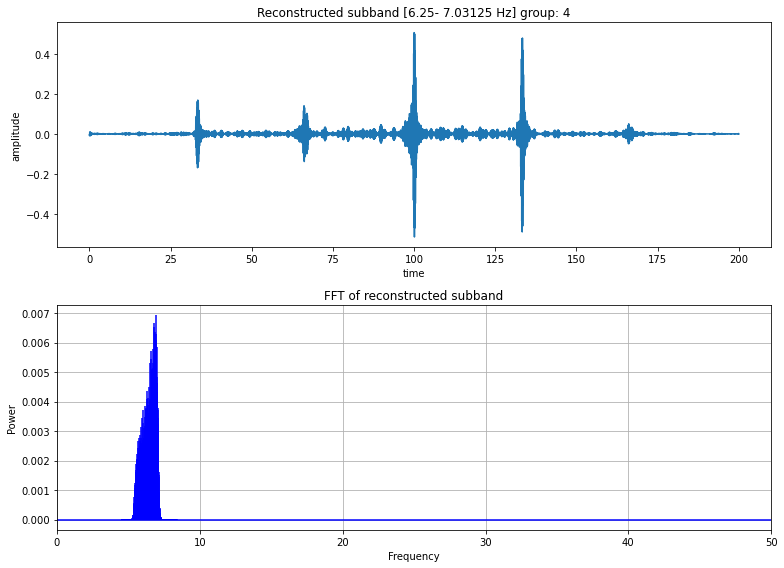

energy of recovered signal: 0.0010209914364572618
kurtosis of recovered signal: 102.8942986510373
crest factor of recovered signal: 9.21478839895171

energy of node coefficients: 0.055287807902866686
kurtosis of node coefficients: 34.74653777624941
crest factor of node coefficients: 12.64446686380699


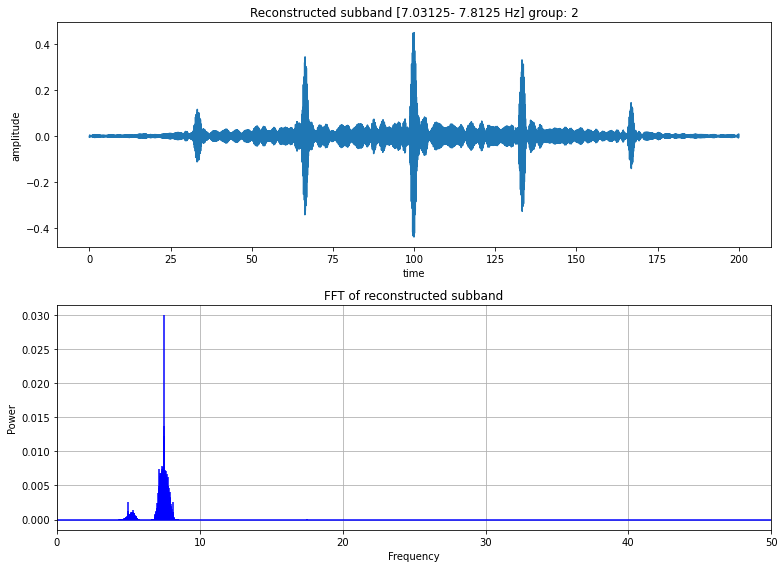

energy of recovered signal: 0.0016134892601122354
kurtosis of recovered signal: 32.14780933932631
crest factor of recovered signal: 7.0552824899751085

energy of node coefficients: 0.08730808461042305
kurtosis of node coefficients: 15.50608883107893
crest factor of node coefficients: 11.049570172268625


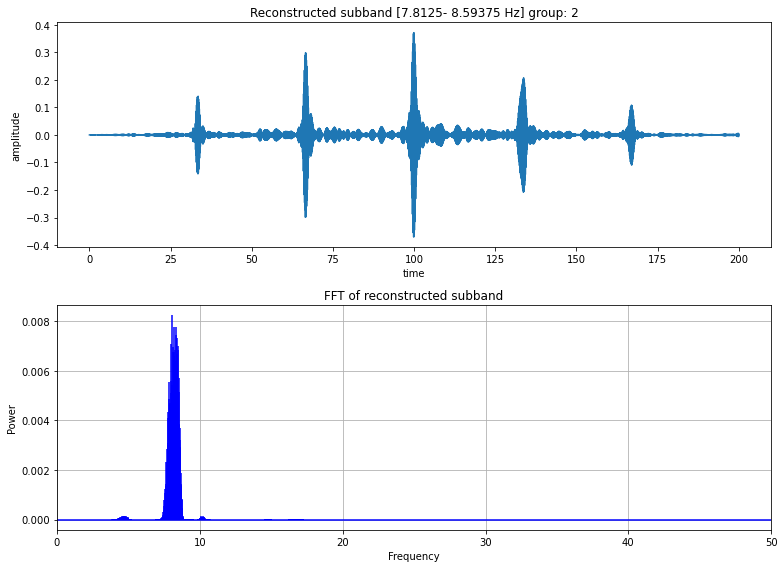

energy of recovered signal: 0.0009292310805682094
kurtosis of recovered signal: 45.276223788350585
crest factor of recovered signal: 6.564938657247876

energy of node coefficients: 0.05027396151679775
kurtosis of node coefficients: 35.56257687635445
crest factor of node coefficients: 13.169126053619378


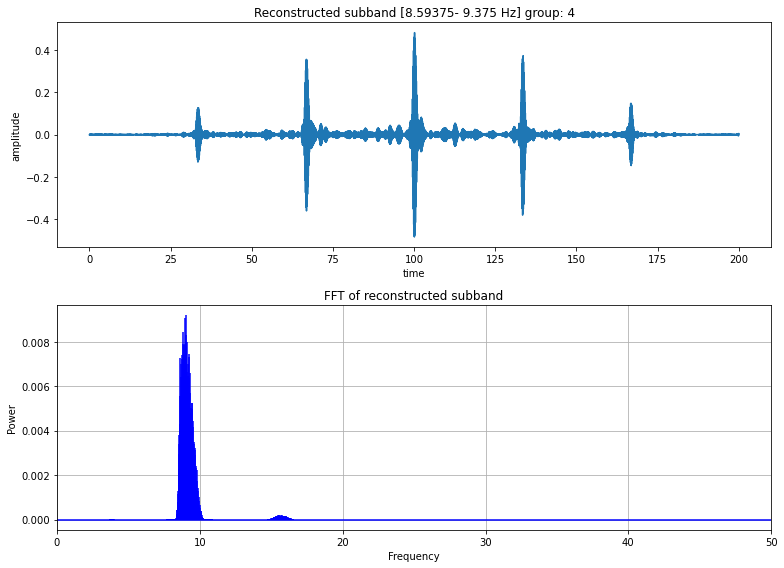

energy of recovered signal: 0.001271806751277517
kurtosis of recovered signal: 64.31609294200045
crest factor of recovered signal: 8.18707346887103

energy of node coefficients: 0.06877782424810194
kurtosis of node coefficients: 27.78984626420265
crest factor of node coefficients: 12.28187372867642


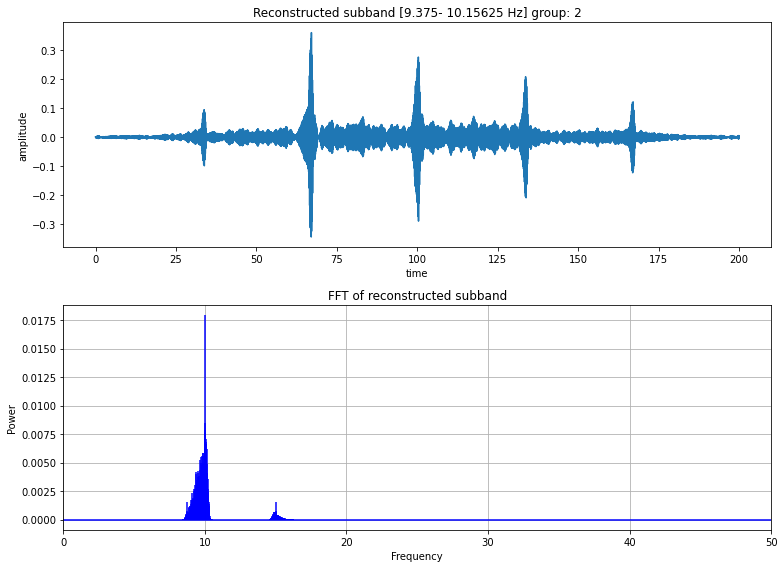

energy of recovered signal: 0.0008966217905976185
kurtosis of recovered signal: 29.044531026670285
crest factor of recovered signal: 6.369168741333787

energy of node coefficients: 0.04851433426927422
kurtosis of node coefficients: 12.160837756357106
crest factor of node coefficients: 9.896217258071182


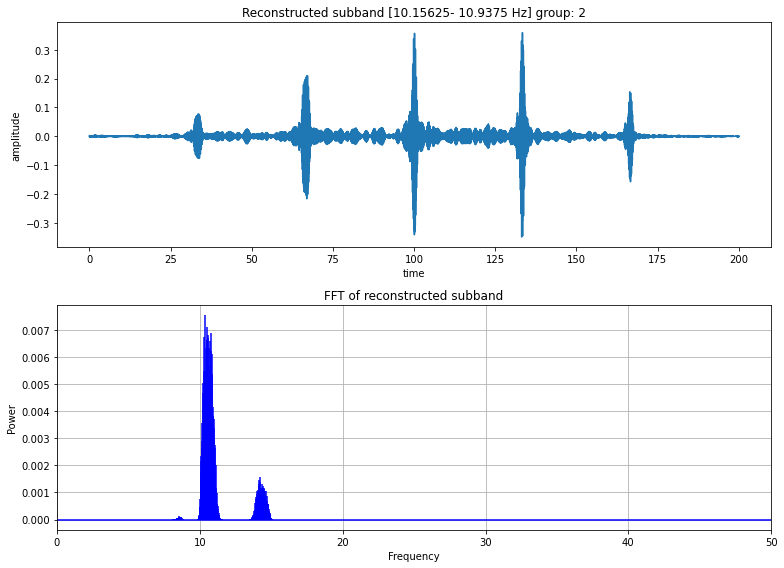

energy of recovered signal: 0.00084713473004399
kurtosis of recovered signal: 43.978271101396004
crest factor of recovered signal: 6.468014786105308

energy of node coefficients: 0.04581305970224542
kurtosis of node coefficients: 63.21168886244871
crest factor of node coefficients: 13.699269557032686


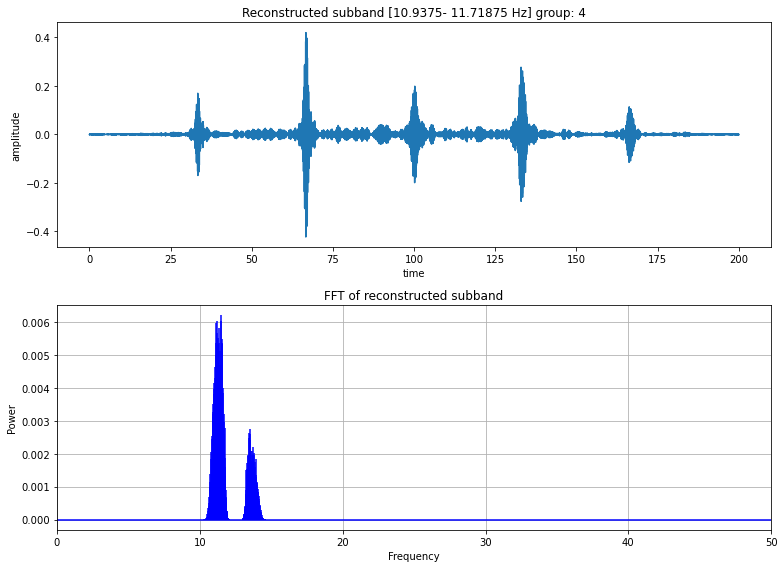

energy of recovered signal: 0.0007362765348620459
kurtosis of recovered signal: 53.69952684541543
crest factor of recovered signal: 8.202557837529746

energy of node coefficients: 0.039811229268427416
kurtosis of node coefficients: 19.280205077129096
crest factor of node coefficients: 10.26050880934168


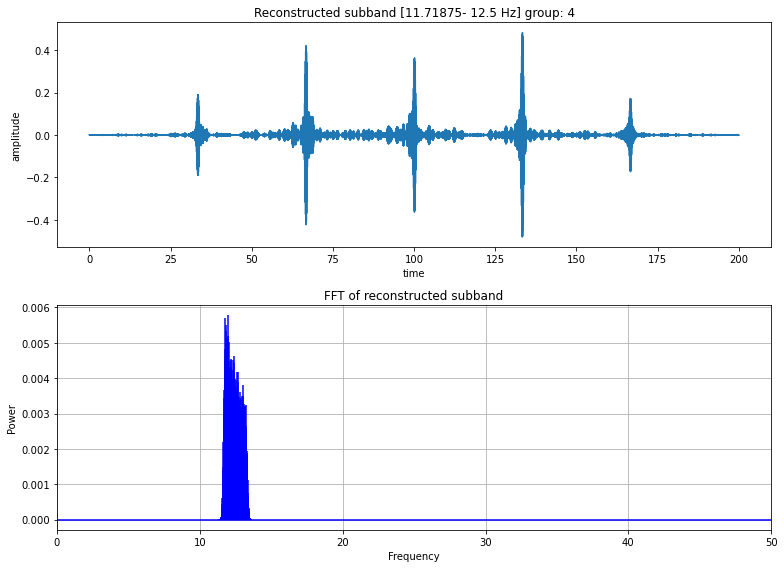

energy of recovered signal: 0.0010206040723925987
kurtosis of recovered signal: 78.91485436905532
crest factor of recovered signal: 8.630864426994538

energy of node coefficients: 0.05517897657320439
kurtosis of node coefficients: 25.295129318935764
crest factor of node coefficients: 12.329060974848822


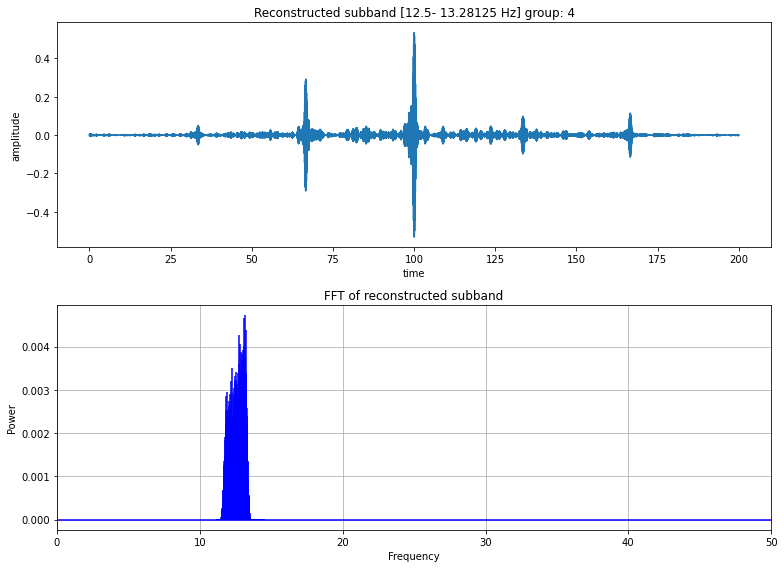

energy of recovered signal: 0.0006955820315710677
kurtosis of recovered signal: 150.4414593890391
crest factor of recovered signal: 10.345826942365218

energy of node coefficients: 0.03772288961178216
kurtosis of node coefficients: 63.34683259276416
crest factor of node coefficients: 14.515558129718274


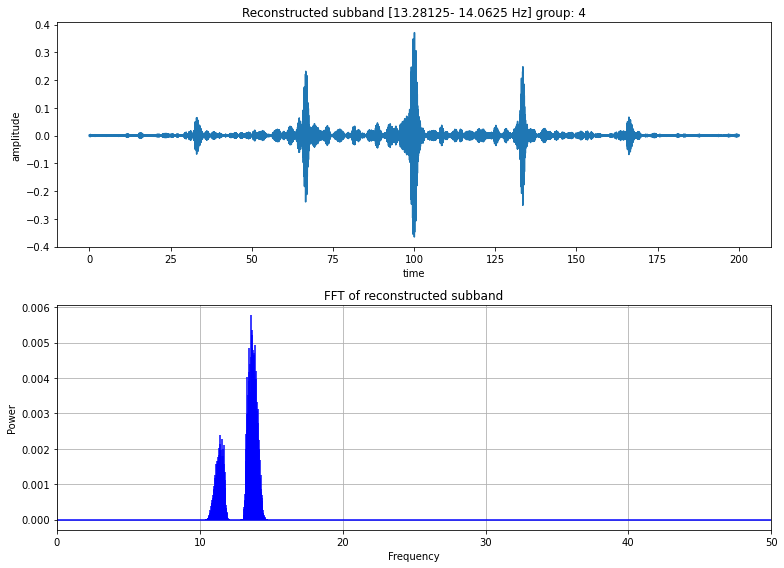

energy of recovered signal: 0.0006010530665055447
kurtosis of recovered signal: 61.08234912616888
crest factor of recovered signal: 7.4901524385343325

energy of node coefficients: 0.032634957869547315
kurtosis of node coefficients: 30.835212654895088
crest factor of node coefficients: 10.977219211156521


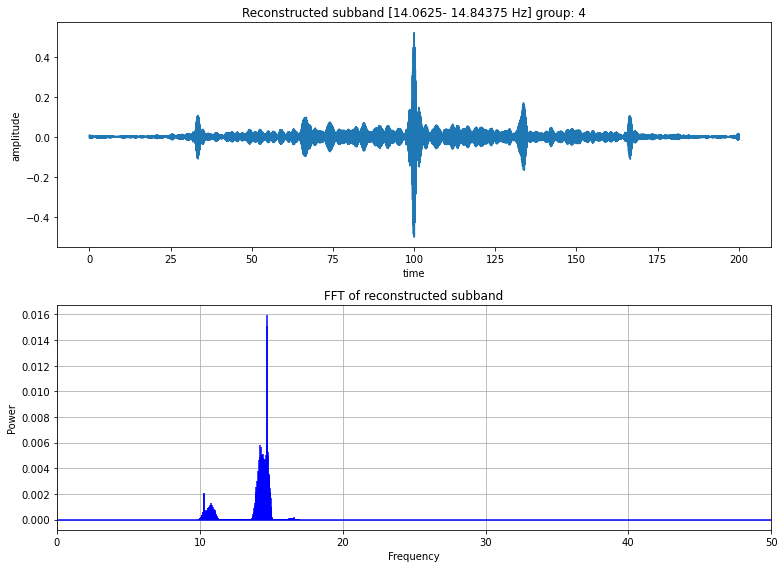

energy of recovered signal: 0.0009650829385675106
kurtosis of recovered signal: 63.77896561870449
crest factor of recovered signal: 9.419784304620979

energy of node coefficients: 0.053180213652364285
kurtosis of node coefficients: 55.039637820937614
crest factor of node coefficients: 15.125074118850698


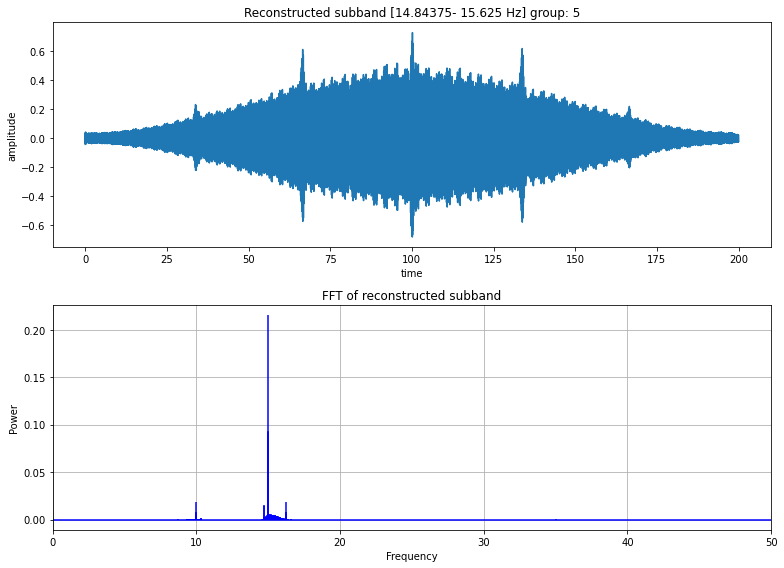

energy of recovered signal: 0.033139610824730374
kurtosis of recovered signal: 0.06854357238572772
crest factor of recovered signal: 4.654634098720545

energy of node coefficients: 1.7952013096135766
kurtosis of node coefficients: 0.5082073955982969
crest factor of node coefficients: 12.549284269477255


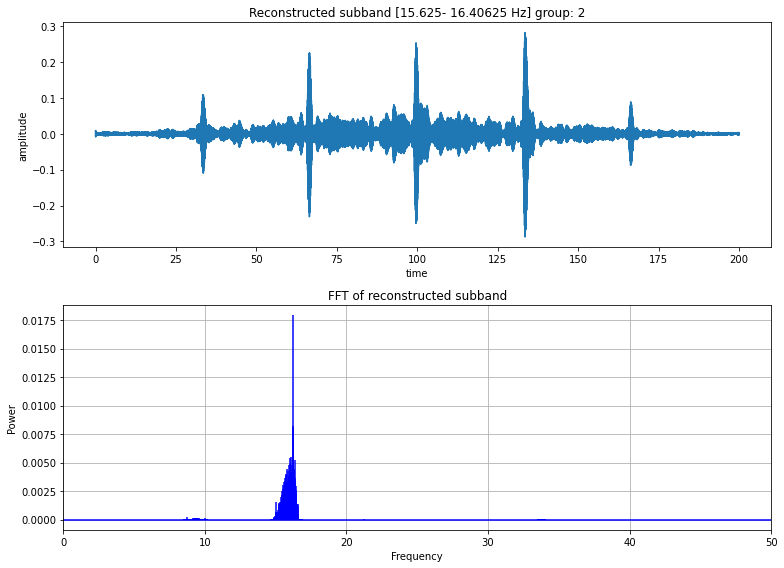

energy of recovered signal: 0.0007828546807762625
kurtosis of recovered signal: 23.00297531054743
crest factor of recovered signal: 4.710231166930331

energy of node coefficients: 0.04278271614394331
kurtosis of node coefficients: 10.00035669813807
crest factor of node coefficients: 8.966620362822184


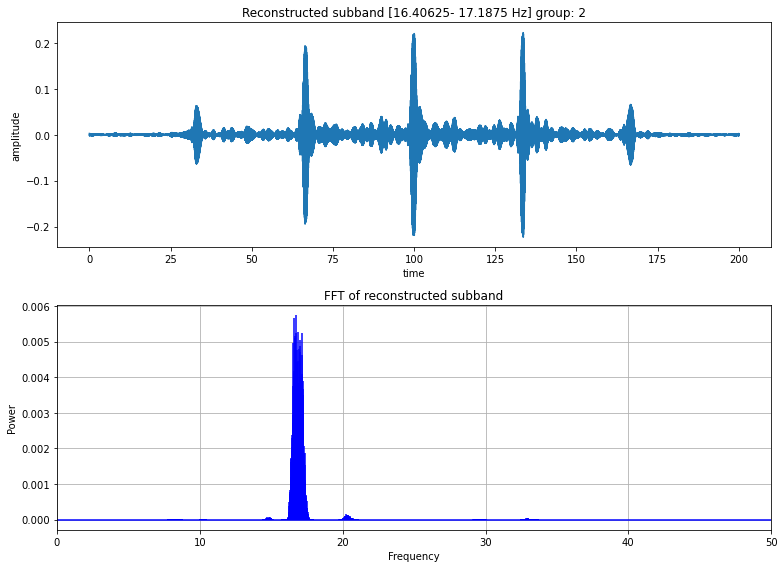

energy of recovered signal: 0.0005234149899416982
kurtosis of recovered signal: 38.70648633435899
crest factor of recovered signal: 3.362203386346491

energy of node coefficients: 0.028432166696250486
kurtosis of node coefficients: 41.543813053732556
crest factor of node coefficients: 11.860507049792632


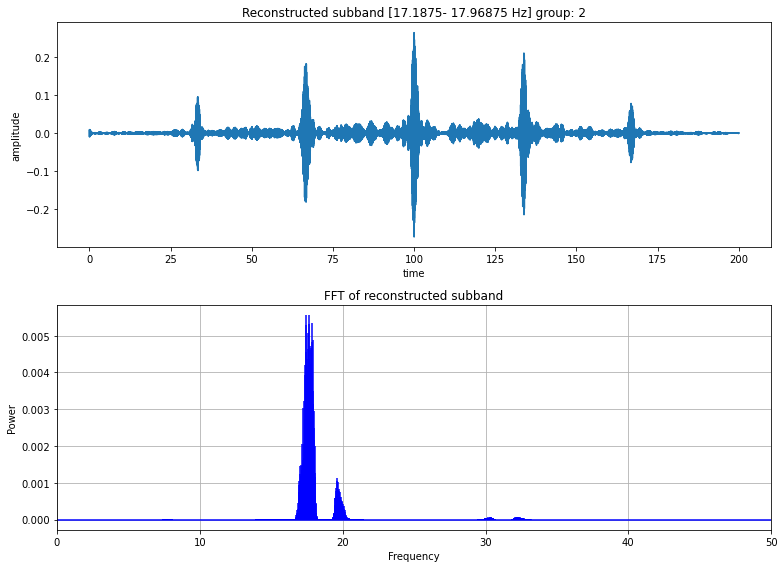

energy of recovered signal: 0.0004751965199310019
kurtosis of recovered signal: 37.670346094212626
crest factor of recovered signal: 5.313179721112029

energy of node coefficients: 0.02574089077471213
kurtosis of node coefficients: 14.187352076795644
crest factor of node coefficients: 7.98854817491733


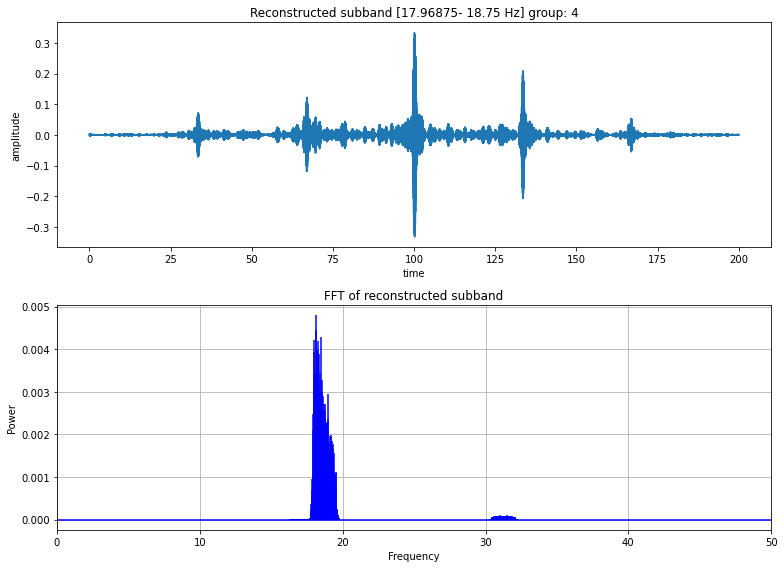

energy of recovered signal: 0.00041712329797590907
kurtosis of recovered signal: 81.51466466703357
crest factor of recovered signal: 7.3622751544700735

energy of node coefficients: 0.022651233003714518
kurtosis of node coefficients: 31.96751076522903
crest factor of node coefficients: 10.537088514061272


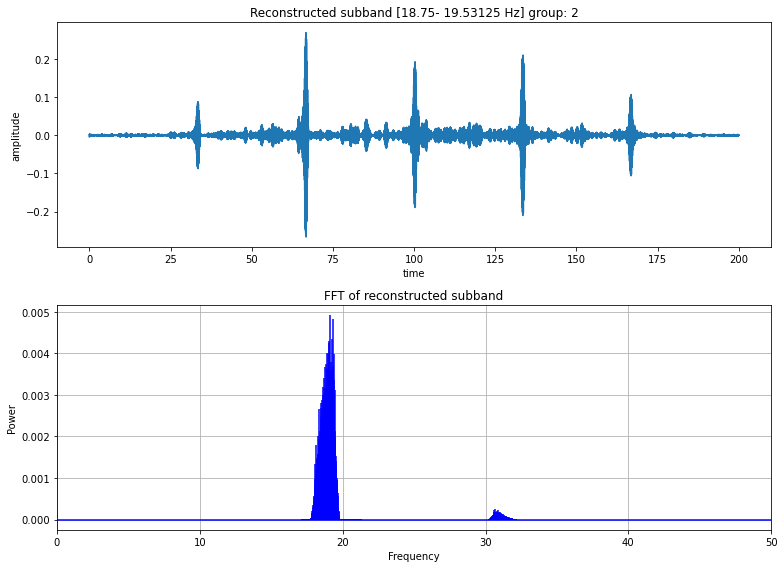

energy of recovered signal: 0.0003787304250002423
kurtosis of recovered signal: 57.01396255754212
crest factor of recovered signal: 5.691371676173151

energy of node coefficients: 0.02049582149765824
kurtosis of node coefficients: 28.180369960930147
crest factor of node coefficients: 10.412569845297007


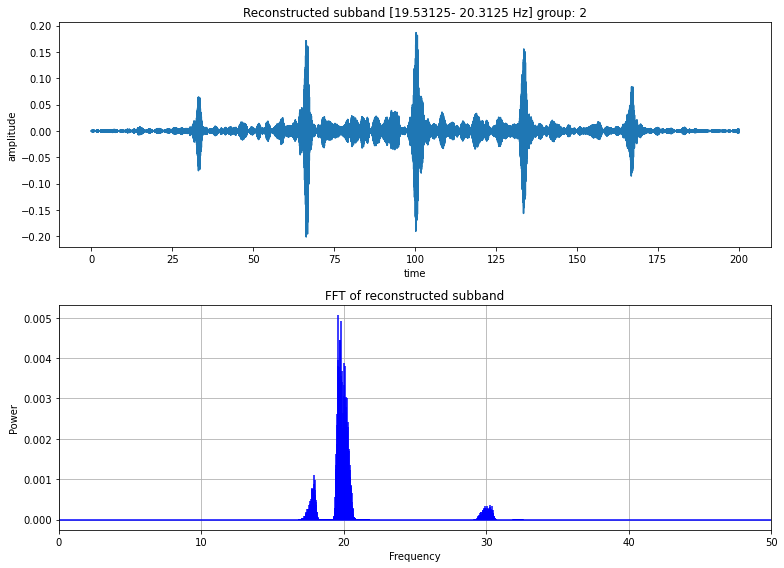

energy of recovered signal: 0.00031325685058665264
kurtosis of recovered signal: 33.860648287643016
crest factor of recovered signal: 3.590578170642693

energy of node coefficients: 0.016954487262698742
kurtosis of node coefficients: 14.608016912779284
crest factor of node coefficients: 8.062825390773794


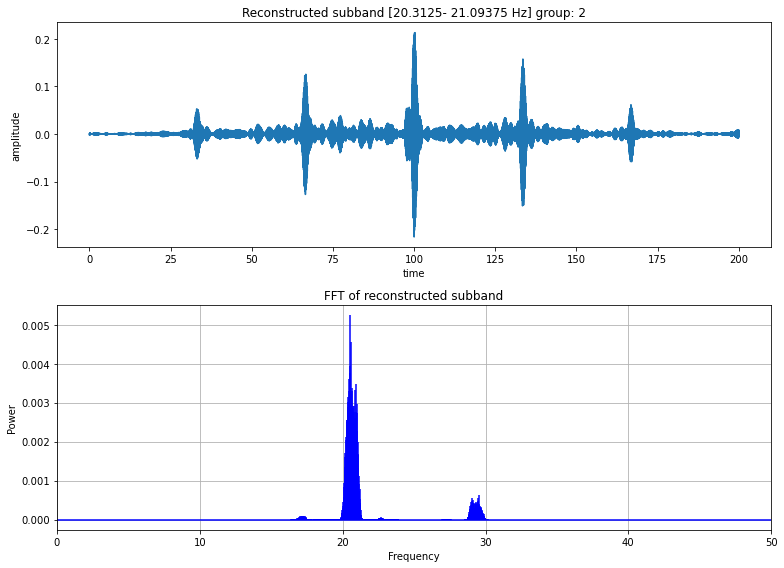

energy of recovered signal: 0.00030023113459685084
kurtosis of recovered signal: 38.8032086589161
crest factor of recovered signal: 4.314868143488207

energy of node coefficients: 0.016359016581445354
kurtosis of node coefficients: 61.25254745302664
crest factor of node coefficients: 12.326945119581138


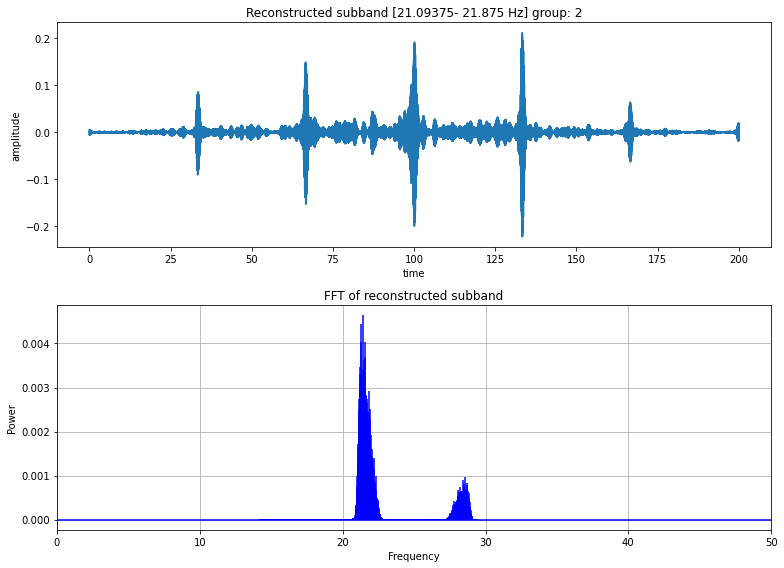

energy of recovered signal: 0.0003493443360898339
kurtosis of recovered signal: 40.19002597099964
crest factor of recovered signal: 4.221643718745522

energy of node coefficients: 0.019049860723053466
kurtosis of node coefficients: 21.098833743647795
crest factor of node coefficients: 9.048298259722491


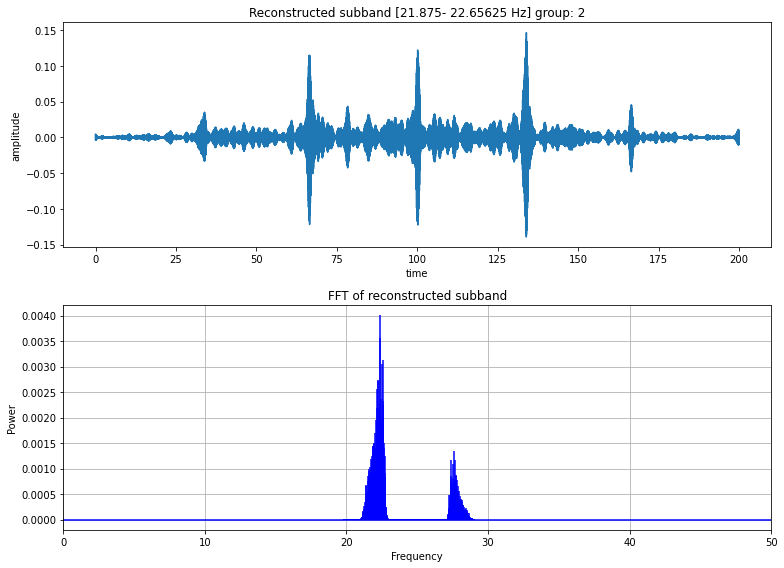

energy of recovered signal: 0.00017380642406412554
kurtosis of recovered signal: 25.653105725357
crest factor of recovered signal: 2.119566179335047

energy of node coefficients: 0.009430082451648638
kurtosis of node coefficients: 24.194001862100684
crest factor of node coefficients: 7.930930649613361


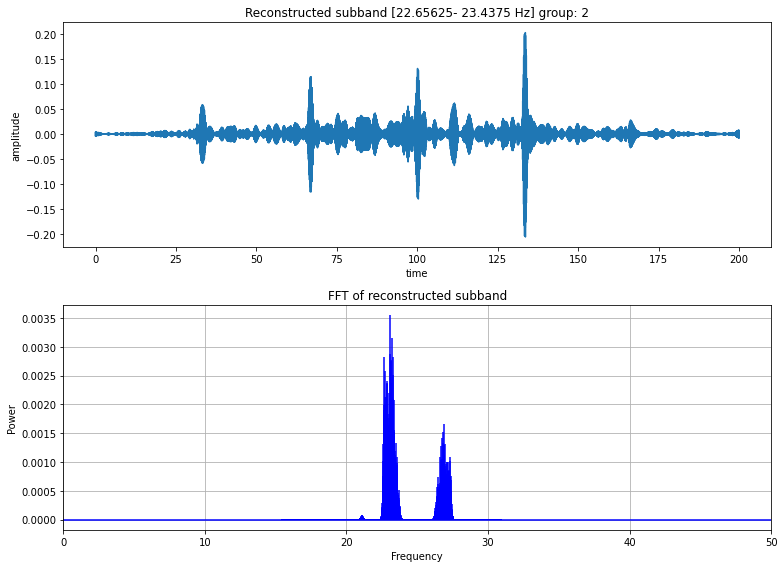

energy of recovered signal: 0.0002289995569437108
kurtosis of recovered signal: 35.651452842895345
crest factor of recovered signal: 4.473018297090444

energy of node coefficients: 0.01248725057878944
kurtosis of node coefficients: 20.666719025164596
crest factor of node coefficients: 9.19818643162076


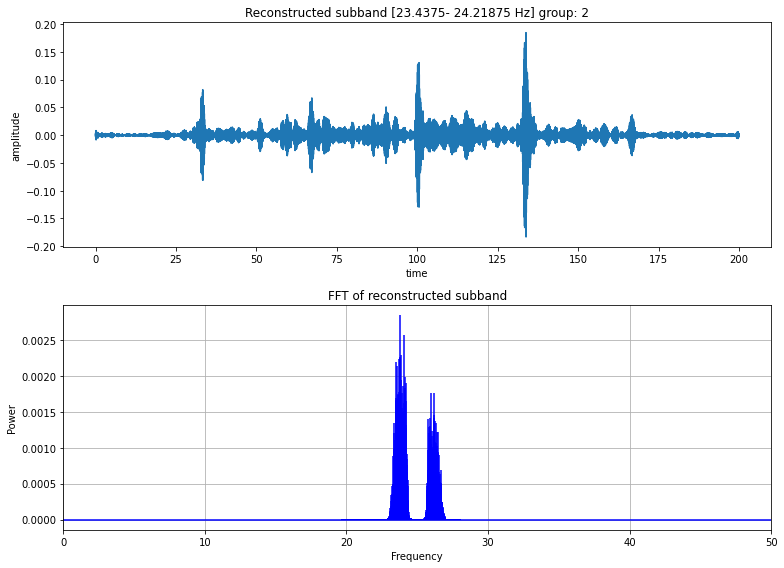

energy of recovered signal: 0.00017188764668883978
kurtosis of recovered signal: 39.96267218746555
crest factor of recovered signal: 4.145737069298958

energy of node coefficients: 0.009660884302550644
kurtosis of node coefficients: 11.61558051429106
crest factor of node coefficients: 7.5791783680816405


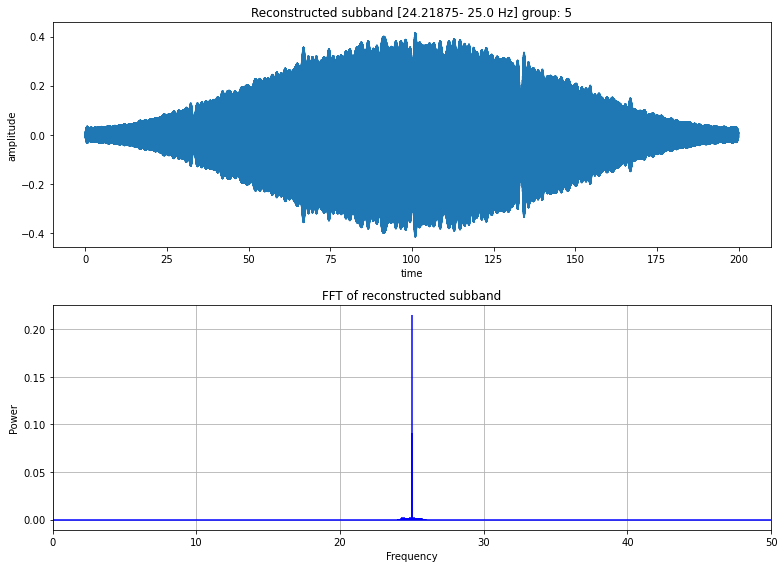

energy of recovered signal: 0.03153183515424285
kurtosis of recovered signal: -0.26980888509916623
crest factor of recovered signal: -0.11425233994266565

energy of node coefficients: 1.7079349273531799
kurtosis of node coefficients: -1.4280784638115003
crest factor of node coefficients: 6.633427984337603


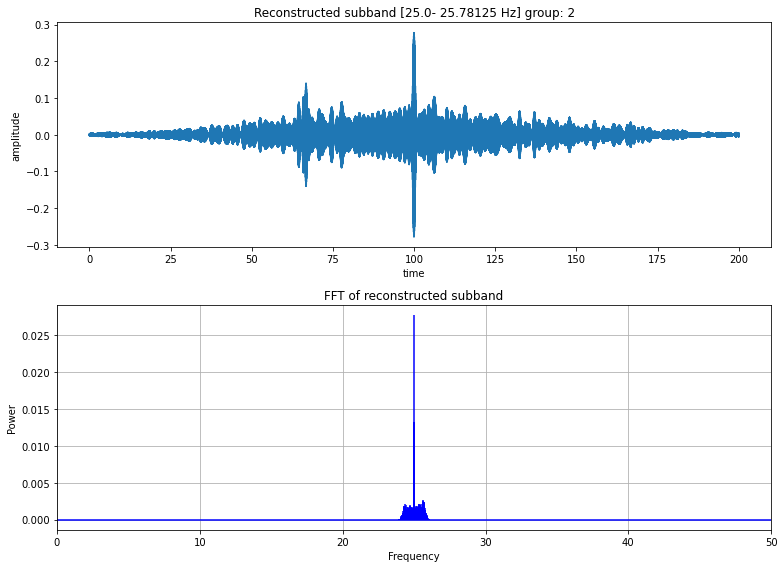

energy of recovered signal: 0.000779379287758087
kurtosis of recovered signal: 11.671684240443636
crest factor of recovered signal: 4.437664686353841

energy of node coefficients: 0.04224735532538333
kurtosis of node coefficients: 12.409909033258996
crest factor of node coefficients: 9.795662097238782


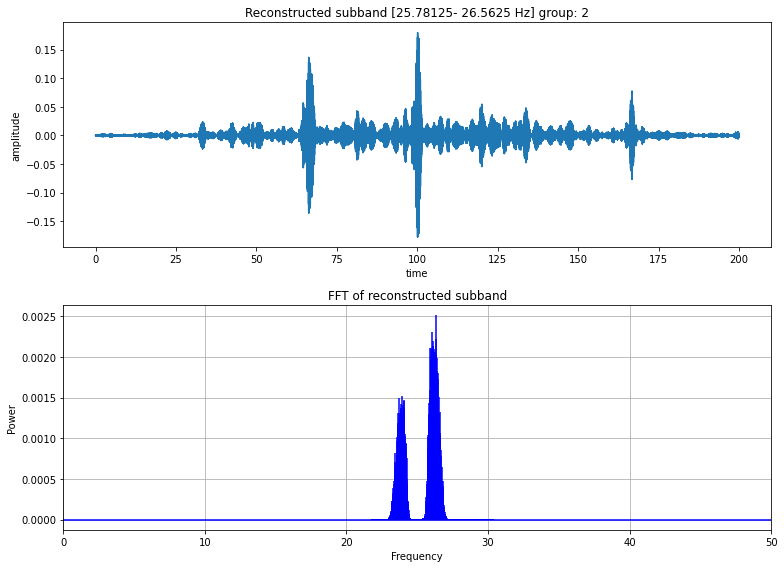

energy of recovered signal: 0.0001852898630921547
kurtosis of recovered signal: 38.895406664489144
crest factor of recovered signal: 3.757791176332103

energy of node coefficients: 0.010088602341897087
kurtosis of node coefficients: 19.769683909953713
crest factor of node coefficients: 7.464033949034655


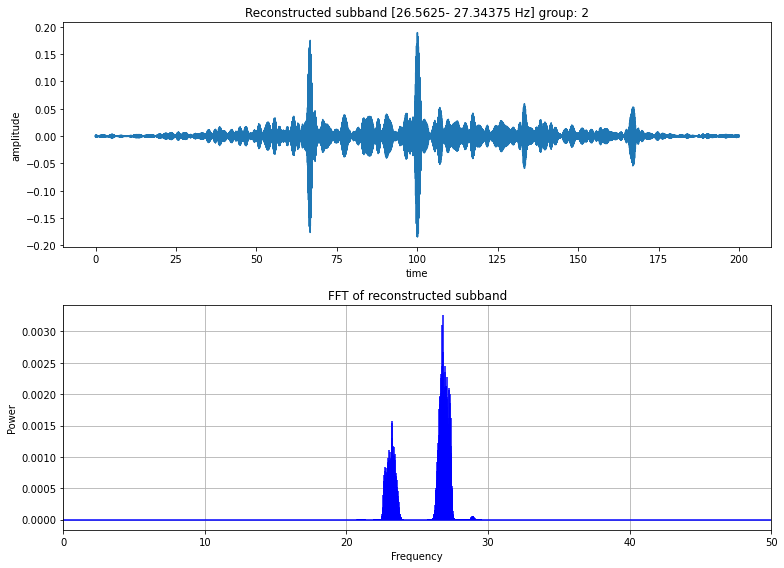

energy of recovered signal: 0.00021612445685681385
kurtosis of recovered signal: 39.55799861834188
crest factor of recovered signal: 3.875764768134932

energy of node coefficients: 0.011701016325525079
kurtosis of node coefficients: 54.583876292783934
crest factor of node coefficients: 11.276792609012809


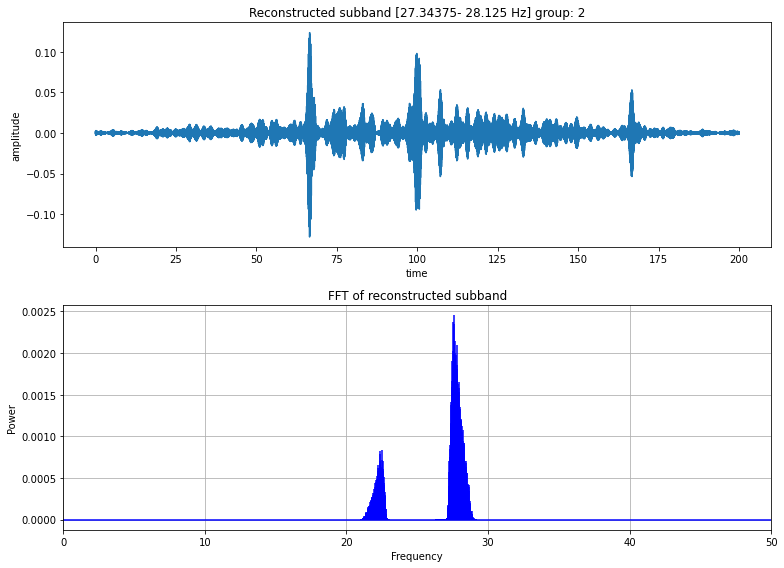

energy of recovered signal: 0.0001298686551470349
kurtosis of recovered signal: 24.7013996788019
crest factor of recovered signal: 1.5852310962372276

energy of node coefficients: 0.0070314005723734
kurtosis of node coefficients: 22.999515122043487
crest factor of node coefficients: 8.487475215909635


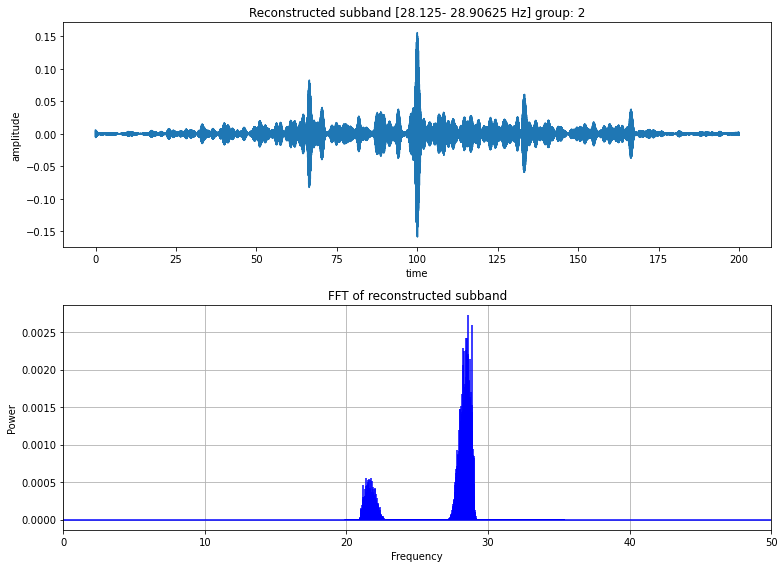

energy of recovered signal: 0.00014682266477342653
kurtosis of recovered signal: 36.371200913842046
crest factor of recovered signal: 3.1730786359075713

energy of node coefficients: 0.007956653883699035
kurtosis of node coefficients: 20.2396776583258
crest factor of node coefficients: 7.2959816784325096


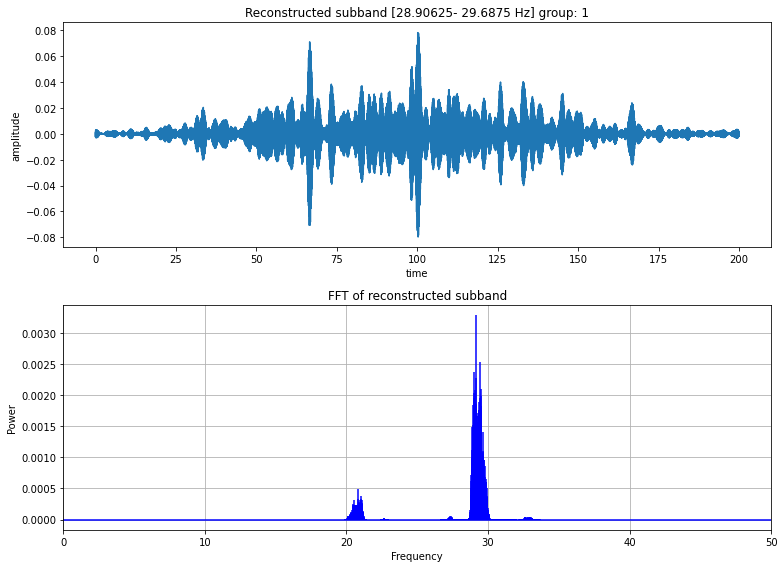

energy of recovered signal: 0.00011539828581885675
kurtosis of recovered signal: 6.63620428518513
crest factor of recovered signal: -2.2747339276575183

energy of node coefficients: 0.006255254859087862
kurtosis of node coefficients: 12.371122275906059
crest factor of node coefficients: 6.064404828118813


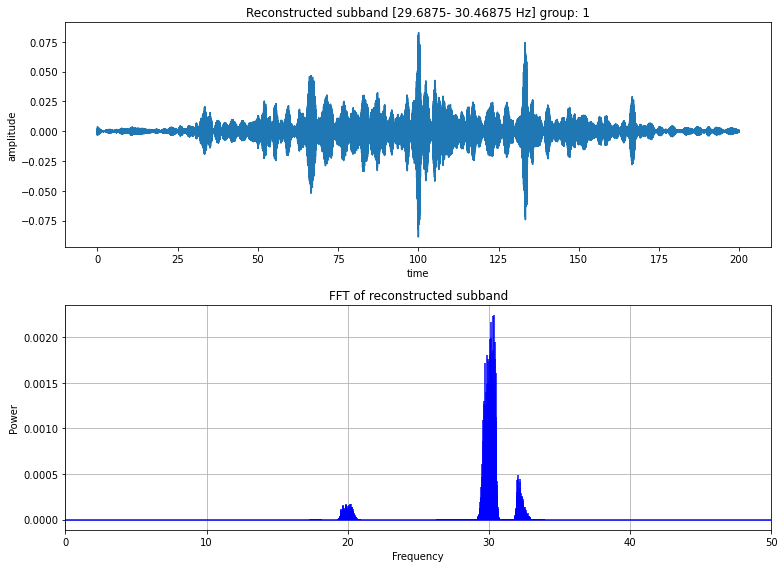

energy of recovered signal: 9.381660109216616e-05
kurtosis of recovered signal: 9.479254437883776
crest factor of recovered signal: -0.8984808739121257

energy of node coefficients: 0.0050820990731813035
kurtosis of node coefficients: 5.253174204050113
crest factor of node coefficients: 2.7243325491747465


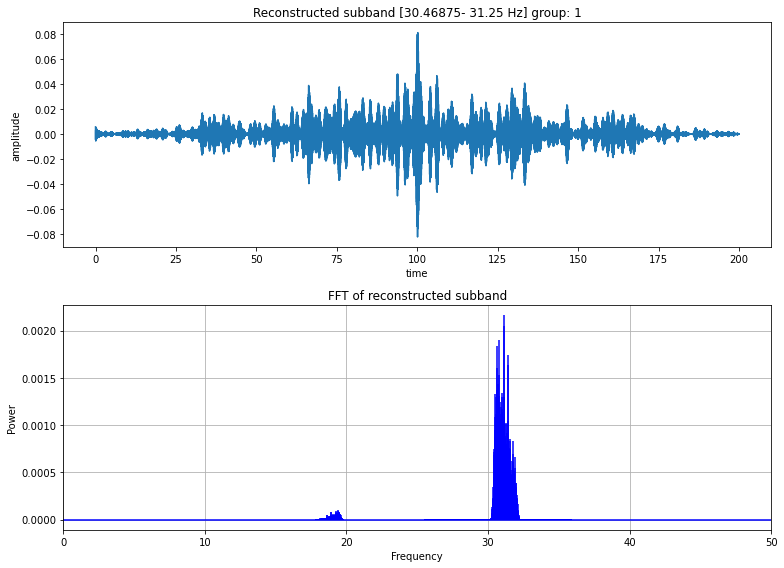

energy of recovered signal: 7.63291201079989e-05
kurtosis of recovered signal: 8.992552875613537
crest factor of recovered signal: -1.1198852228155347

energy of node coefficients: 0.004144043297042447
kurtosis of node coefficients: 6.266017004810674
crest factor of node coefficients: 3.6041548521709226


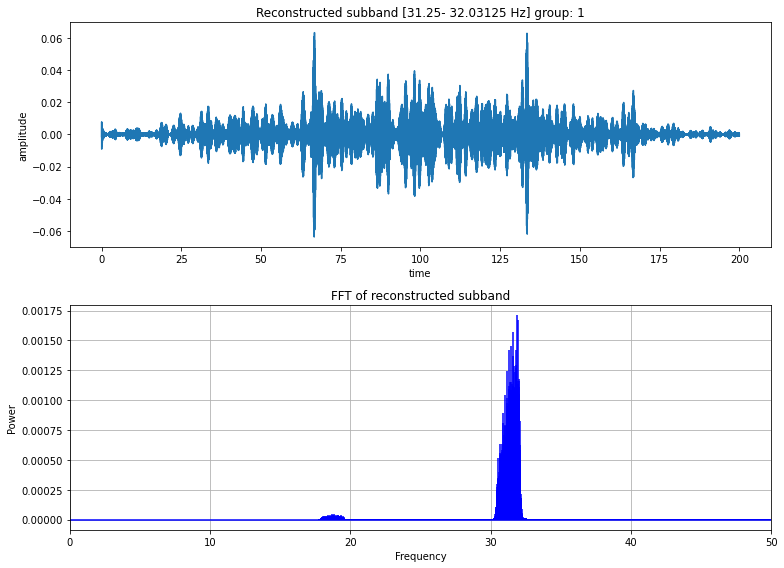

energy of recovered signal: 6.873920053430778e-05
kurtosis of recovered signal: 6.115597727421621
crest factor of recovered signal: -3.1029684297025977

energy of node coefficients: 0.0037863451052013806
kurtosis of node coefficients: 2.875281693563694
crest factor of node coefficients: 0.2850864922691124


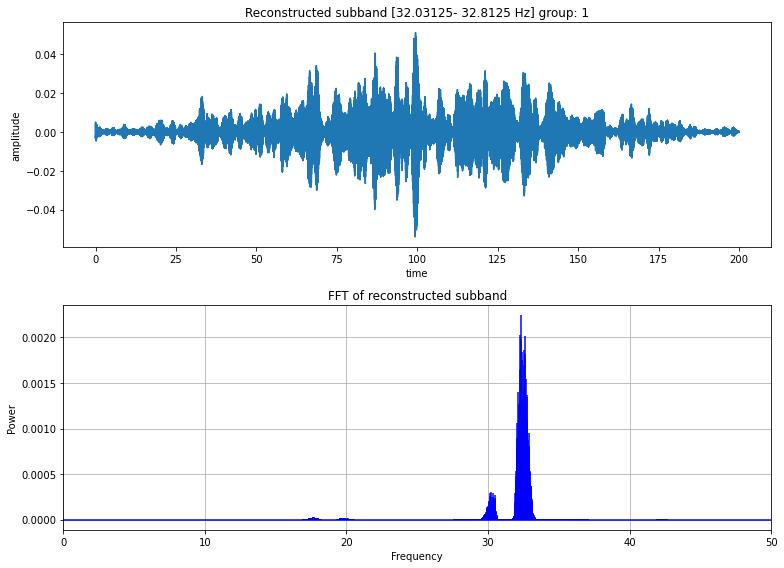

energy of recovered signal: 7.381660798201188e-05
kurtosis of recovered signal: 3.537189747627184
crest factor of recovered signal: -4.675879022617565

energy of node coefficients: 0.003999912272739997
kurtosis of node coefficients: 5.092893039871811
crest factor of node coefficients: 2.7443880540722594


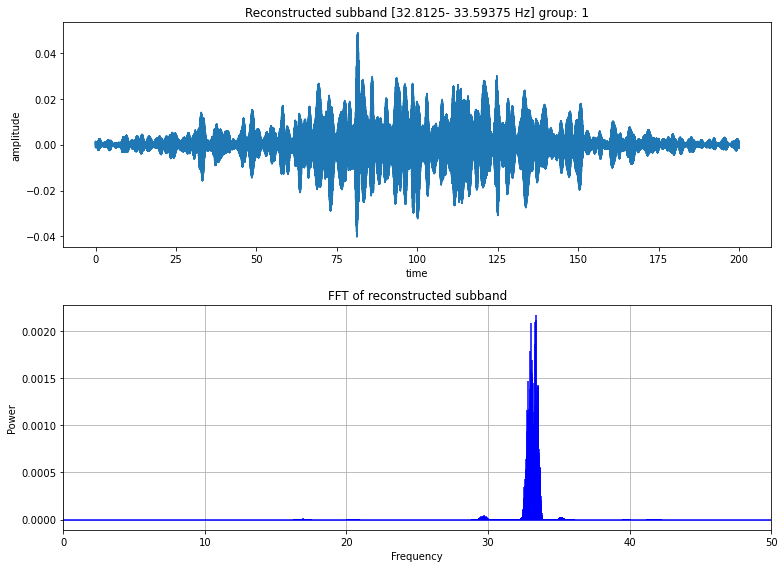

energy of recovered signal: 7.138802865030508e-05
kurtosis of recovered signal: 2.747581925529002
crest factor of recovered signal: -5.504377856362321

energy of node coefficients: 0.003871186437350953
kurtosis of node coefficients: 2.453465793504071
crest factor of node coefficients: -0.036461323350009595


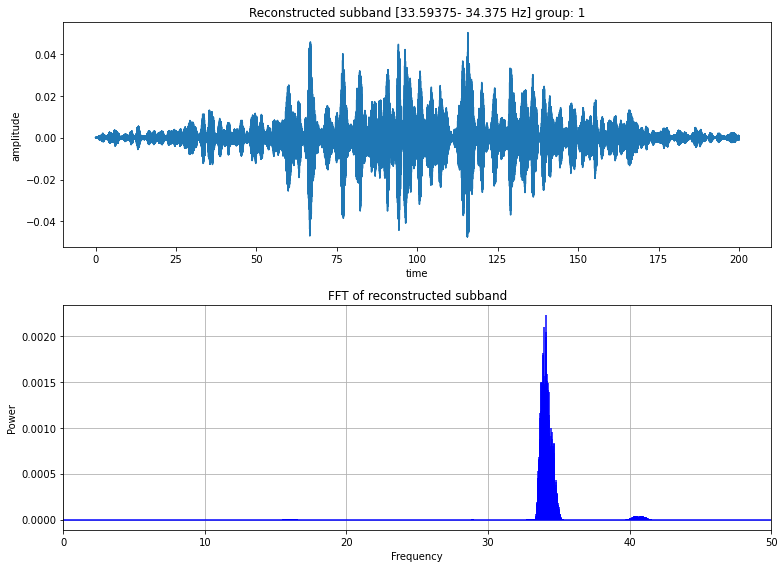

energy of recovered signal: 7.633558839899085e-05
kurtosis of recovered signal: 4.488878166184644
crest factor of recovered signal: -5.39301031180967

energy of node coefficients: 0.0041408920886342095
kurtosis of node coefficients: 3.927270846549945
crest factor of node coefficients: 1.5848734787444394


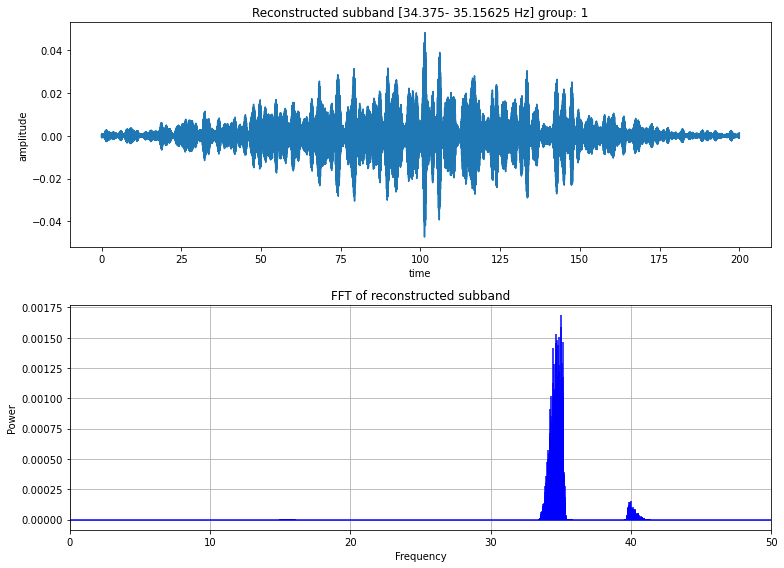

energy of recovered signal: 5.489833225157097e-05
kurtosis of recovered signal: 3.4245774525708486
crest factor of recovered signal: -5.050142500956368

energy of node coefficients: 0.0029804502500509244
kurtosis of node coefficients: 3.3847405377560404
crest factor of node coefficients: 1.1179269032054973


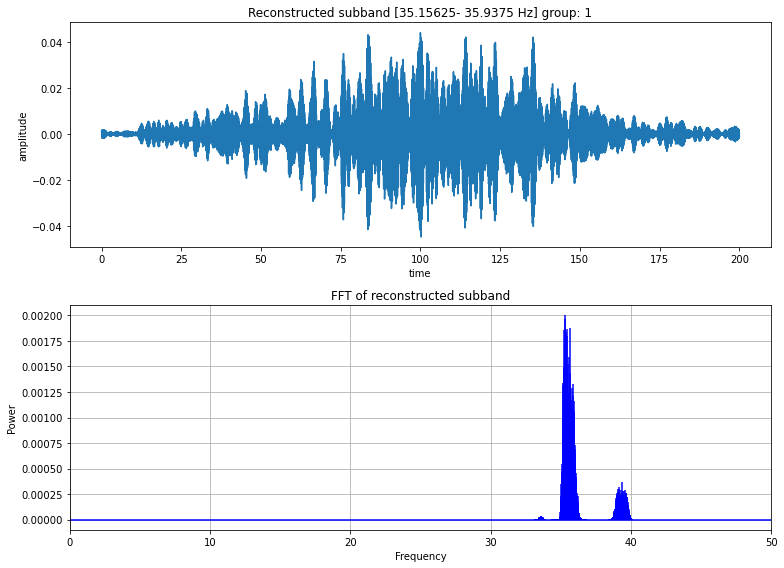

energy of recovered signal: 8.322902134489785e-05
kurtosis of recovered signal: 2.6321976253177537
crest factor of recovered signal: -6.586549076873263

energy of node coefficients: 0.004521539191757334
kurtosis of node coefficients: 3.270494645160264
crest factor of node coefficients: 1.1180845167440958


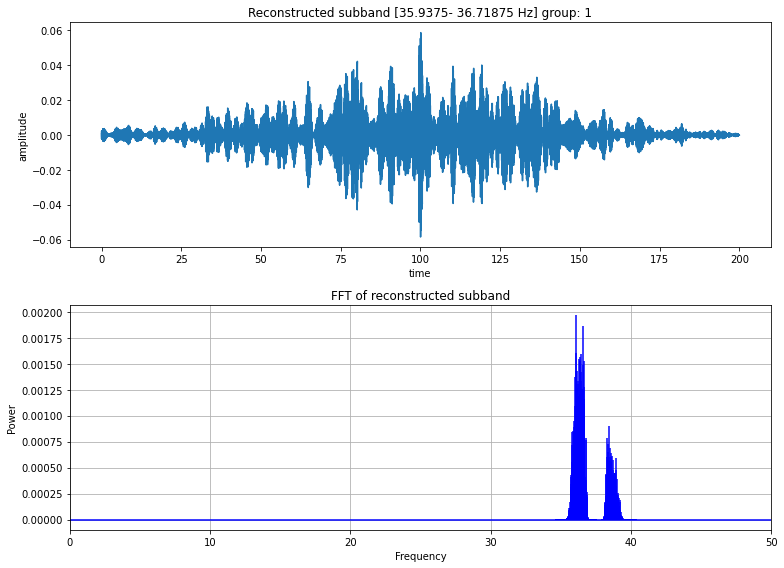

energy of recovered signal: 7.186096422801626e-05
kurtosis of recovered signal: 4.417826662623522
crest factor of recovered signal: -3.9062073608794123

energy of node coefficients: 0.003895308757360565
kurtosis of node coefficients: 2.4102008016759413
crest factor of node coefficients: -0.1669467334901774


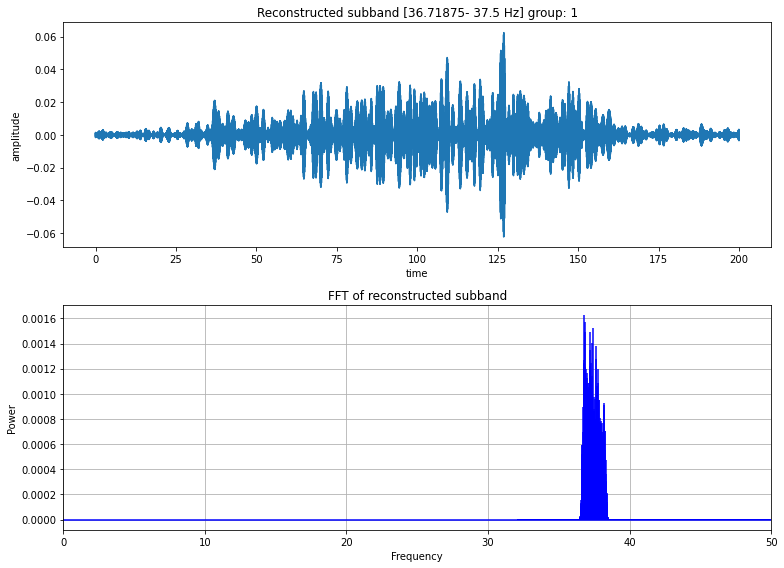

energy of recovered signal: 7.229742559973472e-05
kurtosis of recovered signal: 5.597510430642519
crest factor of recovered signal: -3.378962377639515

energy of node coefficients: 0.003925188724536278
kurtosis of node coefficients: 3.522138657672828
crest factor of node coefficients: 0.8276991347393198


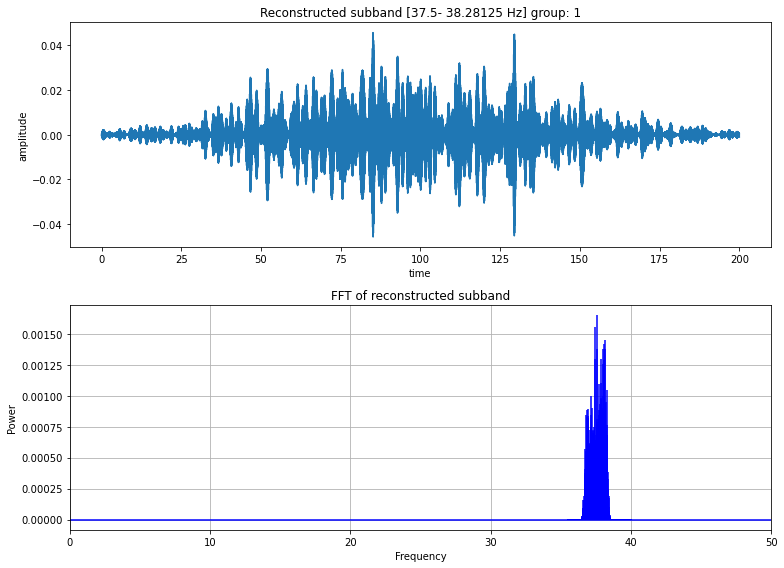

energy of recovered signal: 5.843323183690208e-05
kurtosis of recovered signal: 4.147683840685745
crest factor of recovered signal: -5.627547602714117

energy of node coefficients: 0.0031649032914557907
kurtosis of node coefficients: 2.2247348004284424
crest factor of node coefficients: -1.132795326433784


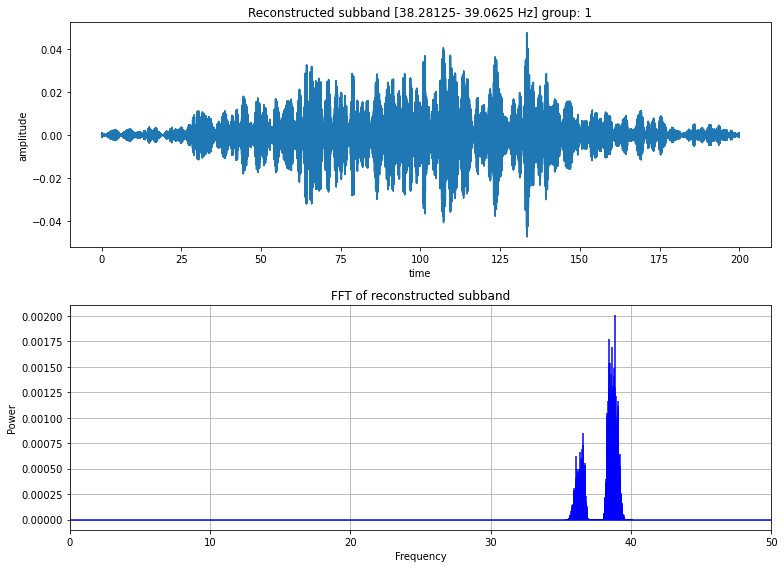

energy of recovered signal: 6.399860242046308e-05
kurtosis of recovered signal: 3.3010411825084445
crest factor of recovered signal: -5.501976712752708

energy of node coefficients: 0.003471011419067832
kurtosis of node coefficients: 2.906930224157133
crest factor of node coefficients: -0.22046169476988745


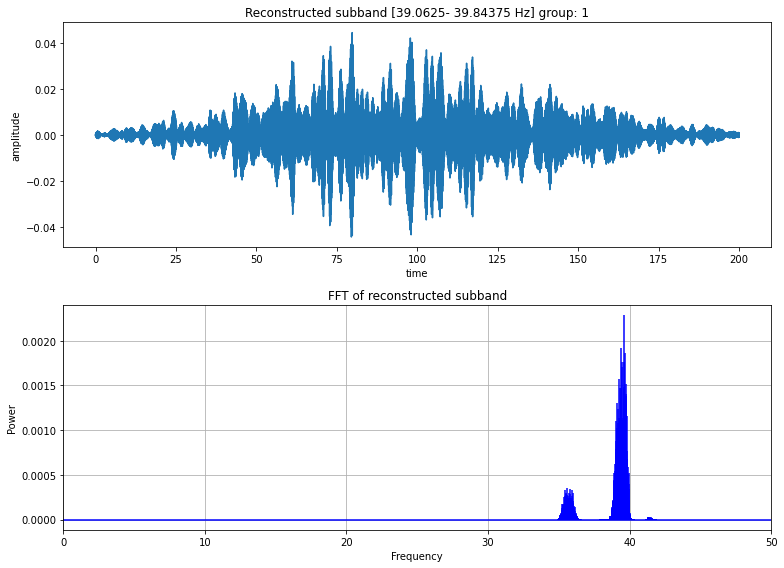

energy of recovered signal: 6.713327110506073e-05
kurtosis of recovered signal: 3.1559692232037646
crest factor of recovered signal: -6.162341271834613

energy of node coefficients: 0.0036353703823725383
kurtosis of node coefficients: 3.9982962926887744
crest factor of node coefficients: 0.9556431371298659


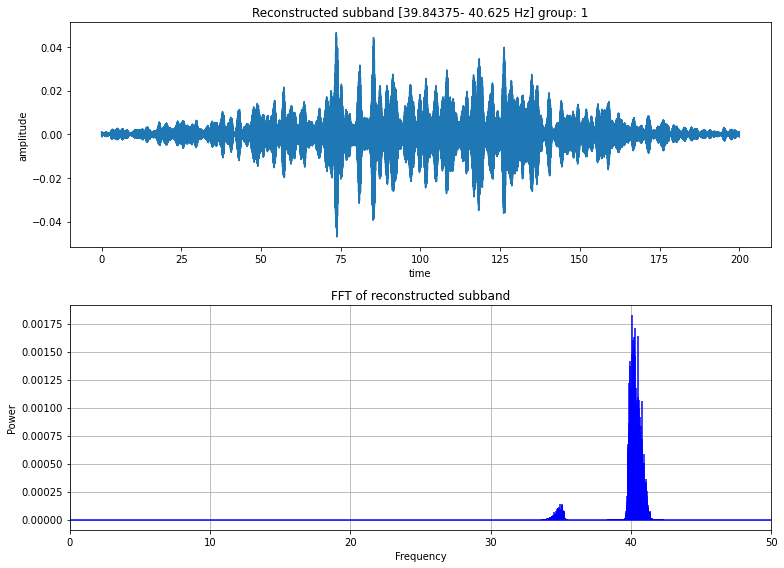

energy of recovered signal: 5.572760564745213e-05
kurtosis of recovered signal: 4.068863865181735
crest factor of recovered signal: -5.28058730330192

energy of node coefficients: 0.0030232320830961544
kurtosis of node coefficients: 3.939540675672312
crest factor of node coefficients: 1.3126241570473407


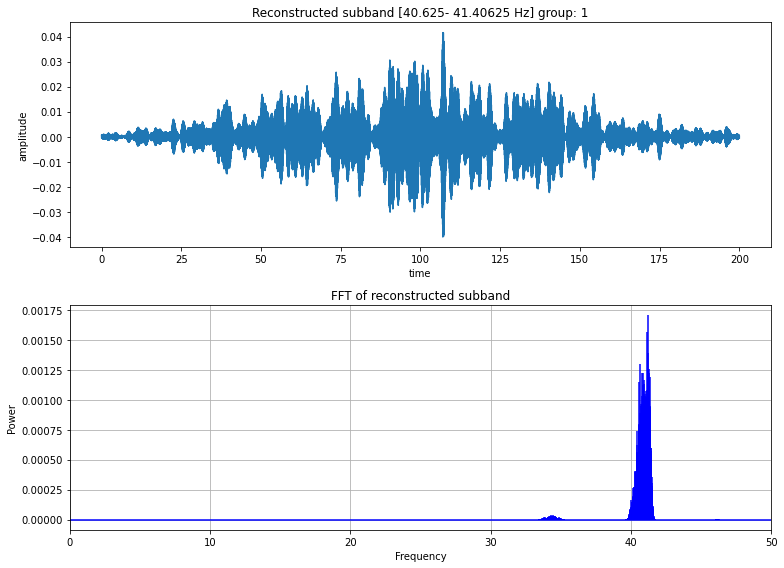

energy of recovered signal: 5.2427183132451117e-05
kurtosis of recovered signal: 2.56895604412923
crest factor of recovered signal: -6.22190435348516

energy of node coefficients: 0.0028403003443853046
kurtosis of node coefficients: 3.0287783343781385
crest factor of node coefficients: 0.3018379397231099


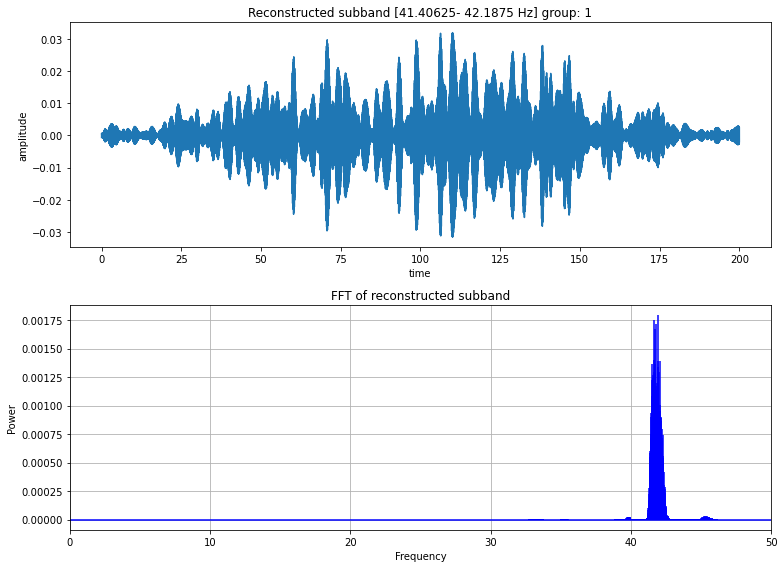

energy of recovered signal: 5.3165340175249226e-05
kurtosis of recovered signal: 2.165184717550659
crest factor of recovered signal: -8.554782352610042

energy of node coefficients: 0.0028968330922671502
kurtosis of node coefficients: 3.9524185570017796
crest factor of node coefficients: -0.03986727631447713


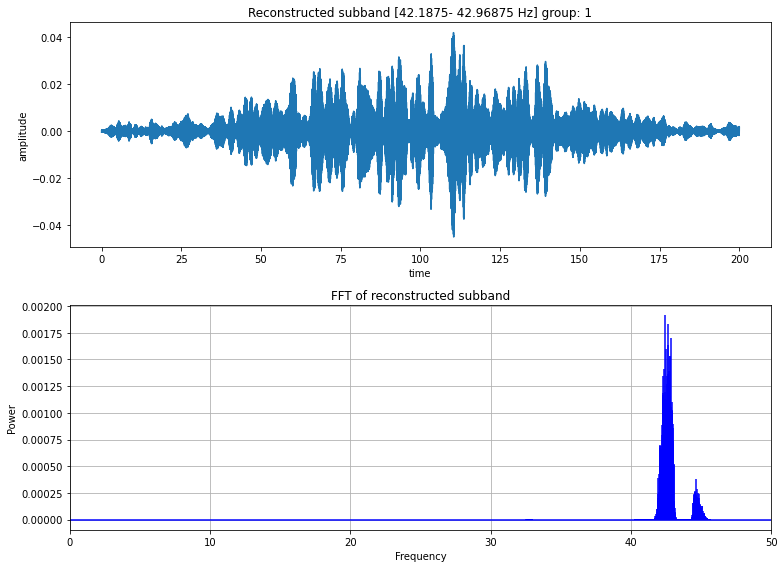

energy of recovered signal: 5.9982499150940174e-05
kurtosis of recovered signal: 2.9057018779377204
crest factor of recovered signal: -5.831583867492568

energy of node coefficients: 0.003257088019486967
kurtosis of node coefficients: 2.8706230310208287
crest factor of node coefficients: 0.8025004909206711


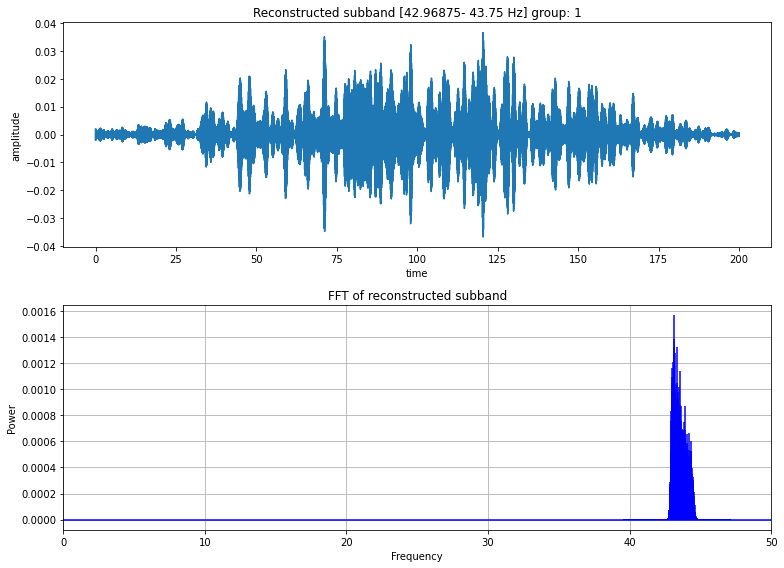

energy of recovered signal: 4.4582620944318724e-05
kurtosis of recovered signal: 2.9713069747543956
crest factor of recovered signal: -6.940001385112955

energy of node coefficients: 0.002419490200124252
kurtosis of node coefficients: 2.358945069485272
crest factor of node coefficients: -1.102644222960472


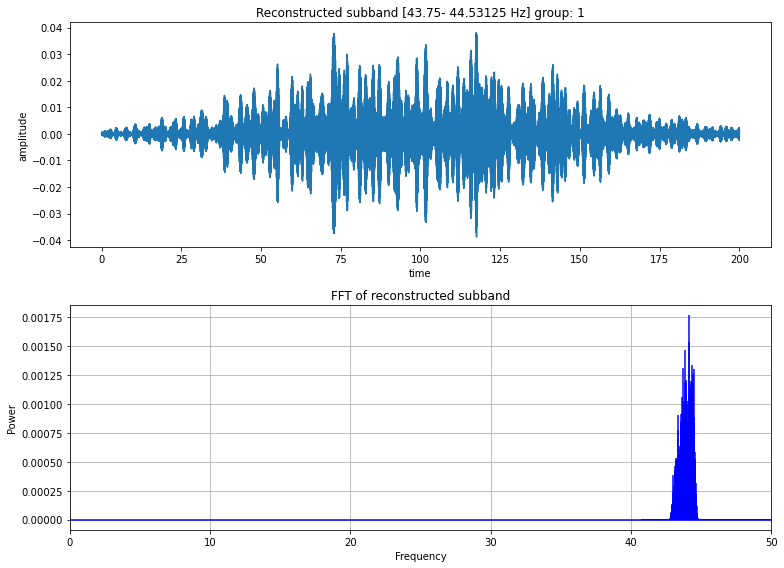

energy of recovered signal: 5.4166305910662154e-05
kurtosis of recovered signal: 3.010614286820714
crest factor of recovered signal: -6.890178221041423

energy of node coefficients: 0.0029339148219839676
kurtosis of node coefficients: 2.597014075889315
crest factor of node coefficients: -0.36227069660192646


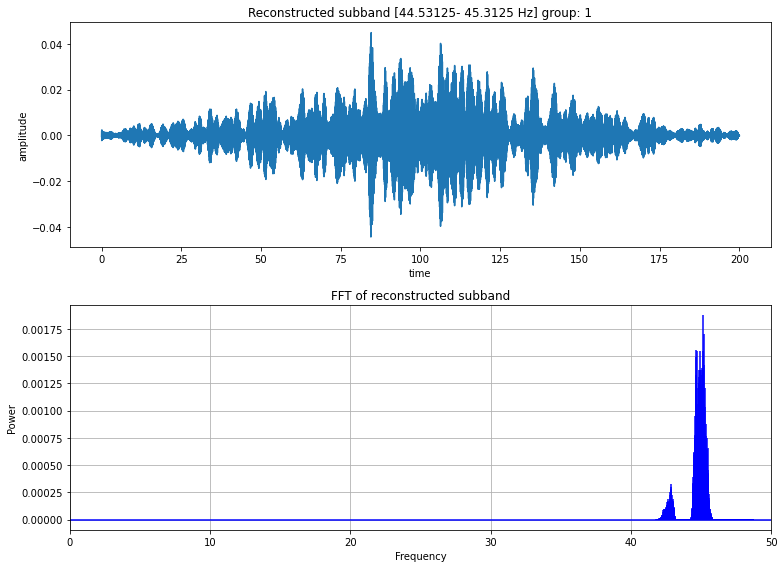

energy of recovered signal: 6.510982891888358e-05
kurtosis of recovered signal: 2.8924467882456577
crest factor of recovered signal: -6.008861925524686

energy of node coefficients: 0.003534662531446754
kurtosis of node coefficients: 2.5467293243968756
crest factor of node coefficients: -0.2315642962058498


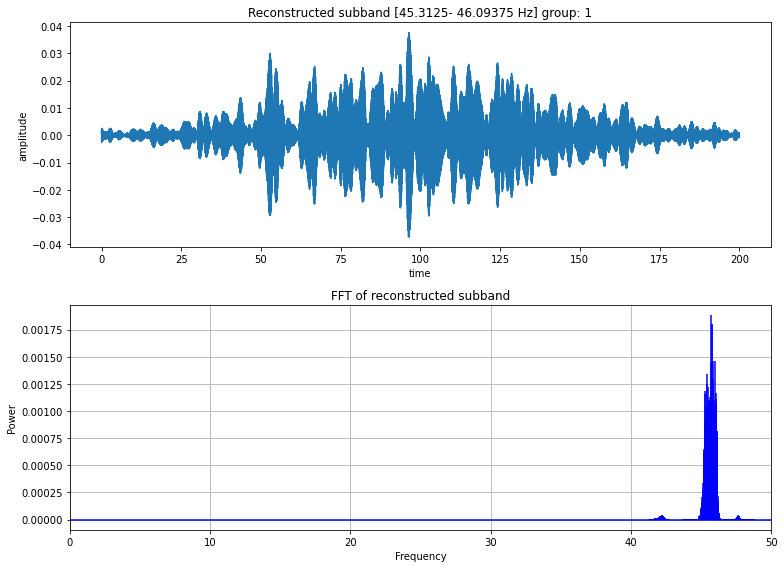

energy of recovered signal: 5.6135716303285604e-05
kurtosis of recovered signal: 2.1556978404535627
crest factor of recovered signal: -7.254444541947044

energy of node coefficients: 0.003040740172554794
kurtosis of node coefficients: 2.4204761669637103
crest factor of node coefficients: -0.6020697852293763


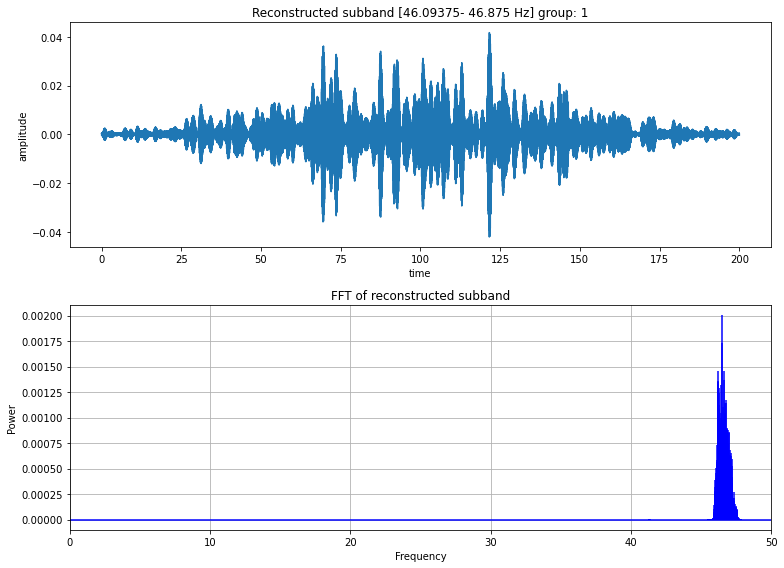

energy of recovered signal: 4.923283755354627e-05
kurtosis of recovered signal: 4.281595797983513
crest factor of recovered signal: -5.965158989255087

energy of node coefficients: 0.0026676882432554298
kurtosis of node coefficients: 3.6378964518750863
crest factor of node coefficients: -0.19993327058785554


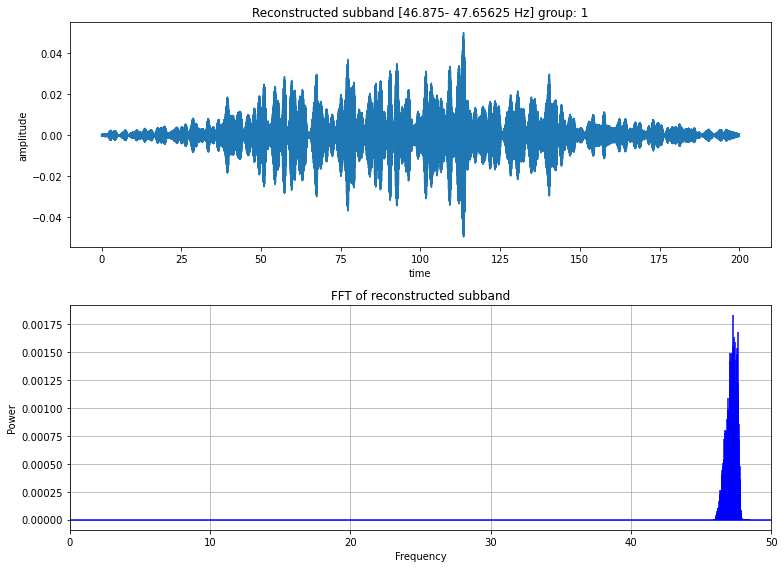

energy of recovered signal: 6.65855815961222e-05
kurtosis of recovered signal: 3.371340766928216
crest factor of recovered signal: -5.1363923210783895

energy of node coefficients: 0.003607800730548225
kurtosis of node coefficients: 4.468410124454009
crest factor of node coefficients: 0.8476092192413304


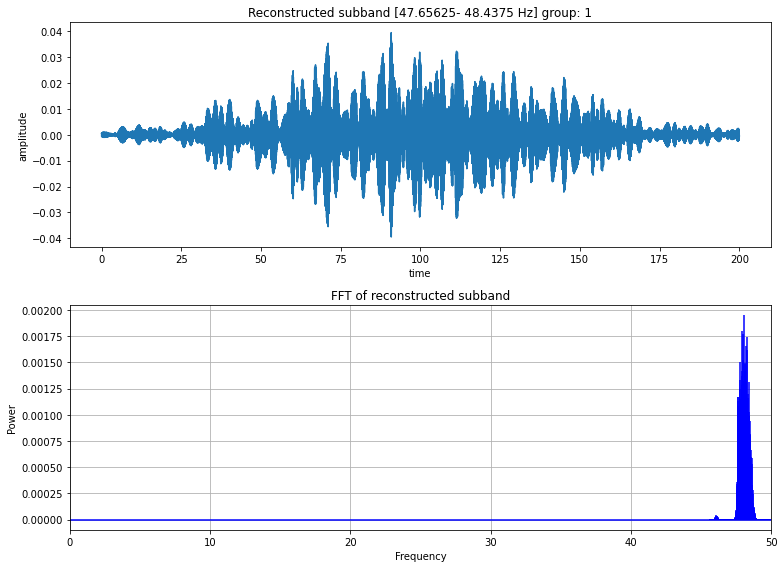

energy of recovered signal: 6.72980763874025e-05
kurtosis of recovered signal: 2.2502070935289584
crest factor of recovered signal: -7.2152635008632355

energy of node coefficients: 0.003643812176565746
kurtosis of node coefficients: 3.9554796762133906
crest factor of node coefficients: 1.0880544980899605


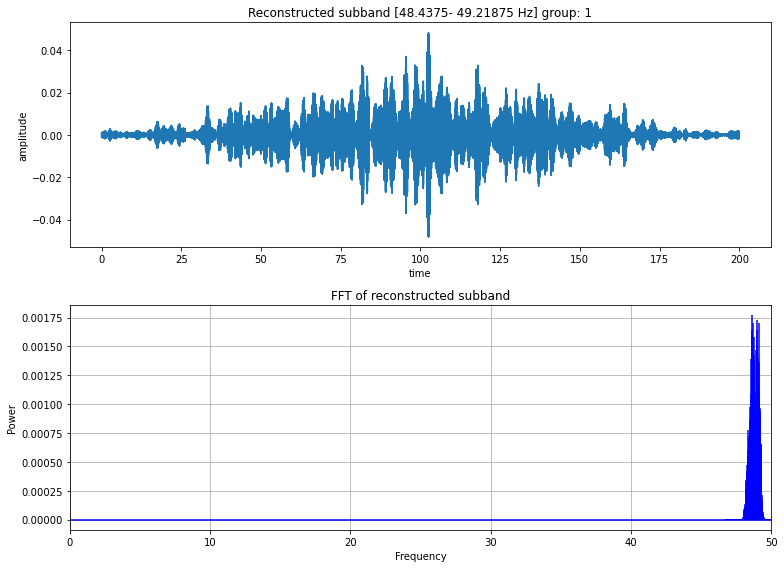

energy of recovered signal: 6.648345719792966e-05
kurtosis of recovered signal: 3.1363543885302327
crest factor of recovered signal: -5.426766384443214

energy of node coefficients: 0.0036015988166237197
kurtosis of node coefficients: 2.9532909075283467
crest factor of node coefficients: -0.04297911706157714


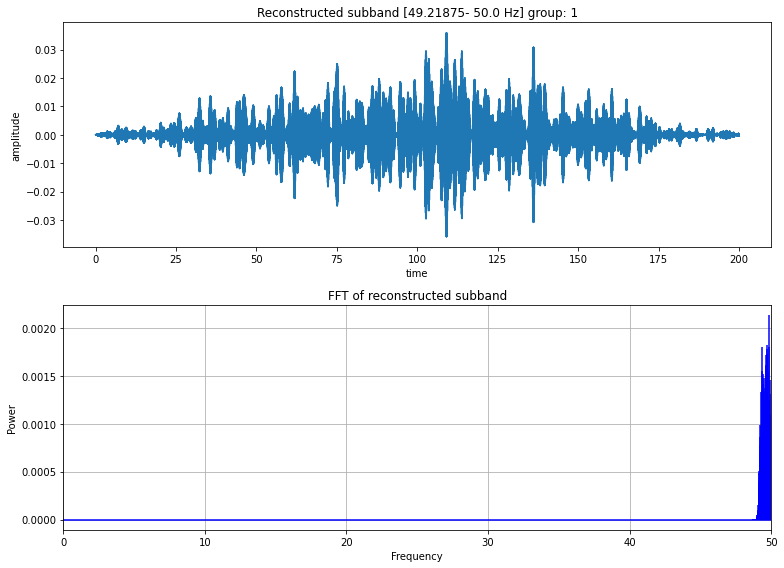

energy of recovered signal: 6.297395343044218e-05
kurtosis of recovered signal: 2.029298332893722
crest factor of recovered signal: -7.866333779219646

energy of node coefficients: 0.003415649927519871
kurtosis of node coefficients: 2.6781194467548666
crest factor of node coefficients: -0.40875135933975126


array([ 0.00449217,  0.00672958,  0.08023728, ..., -0.04149468,
        0.00461834,  0.00625654])

In [68]:
plot_reconstructions(rec,group=reassigned_labels)

# Appendix

### kurtosis and crest factor calculations
testing kurtosis and crest factor calculations on wavelet packet coefficients and reconstructed waves

In [ ]:
# gather data
cent_freqs = [
    round(1 / 2 * sum(node.frequency_range), 1)
    for node in tr_ob.get_level(order="freq")
]
cent_freqs = np.array(cent_freqs)
sparse_cent_freqs = [
    cent_freq if id % 1 == 0 else "" for id, cent_freq in enumerate(cent_freqs)
]
coef_kurtosis = [node.kurtosis for node, _, _ in rec]
kurtosis = [sc.kurtosis(i) for i in rec]

# plot bar chart
fig, ax = plt.subplots(2)
width = 0.4

ax[0].bar(
    cent_freqs, coef_kurtosis, width, align="center", label="kurtosis of coefficients"
)
shifted_freqs = cent_freqs + width
ax[0].bar(
    shifted_freqs,
    kurtosis,
    width,
    align="center",
    label="kurtosis of reconstructed signal",
)

# set the x-axis tick positions and labels
ax[0].set_xticks(cent_freqs + width / 2)
ax[0].set_xticklabels(sparse_cent_freqs, rotation=45, ha="right", fontsize=15)
ax[0].set_yticks(ax[0].get_yticks())
ax[0].set_yticklabels(ax[0].get_yticks(), fontsize=15)

ax[0].set_title(
    "Kurtosis of node coefficients and reconstructed signal at each node", fontsize=25
)
ax[0].set_xlabel("Centre frequency", fontsize=20)
ax[0].set_ylabel("Kurtosis", fontsize=20)
ax[0].legend(fontsize=20)

fig.set_size_inches(18, 16)

scatter = ax[1].scatter(coef_kurtosis, kurtosis, c=cent_freqs)
ax[1].set_title("Kurtosis of node coefficients vs recovered signal", fontsize=25)
ax[1].set_xlabel("Kurtosis of transform coefficients", fontsize=20)
ax[1].set_ylabel("Kurtosis of recovered signal", fontsize=20)

fig.colorbar(scatter, ax=ax[1], label="Frequency [Hz]")

fig.tight_layout()
plt.show()

In [ ]:
# gather data
coef_crest = [node.crest_factor for node, _, _ in rec]
crest = [calc_crest_factor(i) for i in rec]

# plot bar chart
fig, ax = plt.subplots(2)
width = 0.4

ax[0].bar(
    cent_freqs, coef_crest, width, align="center", label="Crest factor of coefficients"
)
shifted_freqs = cent_freqs + width
ax[0].bar(
    shifted_freqs,
    crest,
    width,
    align="center",
    label="Crest factor of reconstructed signal",
)

# set the x-axis tick positions and labels
ax[0].set_xticks(cent_freqs + width / 2)
ax[0].set_xticklabels(sparse_cent_freqs, rotation=45, ha="right", fontsize=15)
ax[0].set_yticks(ax[0].get_yticks())
ax[0].set_yticklabels(ax[0].get_yticks(), fontsize=15)

ax[0].set_title(
    "Crest factor of node coefficients and reconstructed signal at each node",
    fontsize=25,
)
ax[0].set_xlabel("Centre frequency", fontsize=20)
ax[0].set_ylabel("Crest factor [dB]", fontsize=20)
ax[0].legend(fontsize=20)

fig.set_size_inches(18, 16)

scatter = ax[1].scatter(coef_crest, crest, c=cent_freqs)
ax[1].set_title("Crest factor of node coefficients vs recovered signal", fontsize=25)
ax[1].set_xlabel("Crest factor of transform coefficients [dB]", fontsize=20)
ax[1].set_ylabel("Crest factor of recovered signal [dB]", fontsize=20)

fig.colorbar(scatter, ax=ax[1], label="Frequency [Hz]")

fig.tight_layout()
plt.show()

### plot of reconstruction

In [ ]:
# plot sum of highest energy subbands
plt.figure(figsize=(11, 4))
plt.plot(t_plot, partial_rec)
plt.xlabel("time [s]")
plt.ylabel("amplitude [DL]")
plt.title(
    f"sum of {n_highest} highest [{sort_by}] reconstructions vs full reconstruction"
)

# plot full reconstruction
full_rec = inv.inv_dwpt(tr_ob.nodes2data(tr_ob.get_level()), wavelet)
plt.plot(t_plot, full_rec[:signal_length], "--r")
plt.plot(t_plot, data, ":k")
plt.legend(["selective reconstruction", "full reconstruction", "data"], loc="best")
plt.show()

### testing frequency sorting algorithm

In [ ]:
my_frequencies = [node.path for node in tr_ob.get_level(order="freq")]
pywt_nodes = pywt._wavelet_packets.get_graycode_order(levels)
print("my nodes ordered by frequency:", my_frequencies)
print("pywt order:                   ", pywt_nodes)
print(my_frequencies == pywt_nodes)